<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-031-physics-ising-gauge.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 031
<hr/>

# Lab 031 — Ising lattice gauge theory

In Labs 018–020 every phase had an **order parameter**: a local quantity, such as the magnetisation
$m=\frac1N\sum_i s_i$ or the stripe order parameter $m_{\rm str}$, which is non-zero in one phase and zero in the other.
Knowing it, a physicist plots it against temperature and sees the transition; not knowing it, an unsupervised algorithm can still find the
boundary because the raw snapshots of the two phases look different.

There are systems where this picture breaks down completely. In 1971 Wegner introduced Ising models with spins on the **links** of a lattice and
interactions around elementary squares, and showed that they have **phase transitions without local order parameters**
(the phrase is part of the title of his paper, *Duality in generalized Ising models and phase transitions without local order parameters*, F. J. Wegner, J. Math. Phys. **12**, 2259 (1971)). The simplest of them is the **Ising (or $\mathbb Z_2$) lattice gauge theory**,
the simplest *gauge theory*: a theory whose description contains redundant variables that can be changed locally without changing anything physical.
The same mathematical structure, with the two-element group $\mathbb Z_2=\{+1,-1\}$ replaced by continuous groups, underlies the lattice formulation of
quantum chromodynamics (QCD, the theory of quarks and gluons) [Wilson 1974; Kogut 1979].

The model also has a place in the history of machine learning in physics. Carrasquilla and Melko (Nature Physics 2017) trained neural networks to tell low- from high-temperature configurations
of several spin models. For the 2D Ising lattice gauge theory ($16\times16\times2$ link variables, ground-state against infinite-temperature configurations) a fully connected
network trained on raw configurations did not exceed chance-level test accuracy (50%), while a convolutional neural network (CNN) with $2\times2$ filters reached 100%, and further tests showed that it relied on
the local **plaquette constraints** of the model. To understand that result we need the physics of a system in which nothing local can be measured, and this notebook develops it.

We begin in Section 2 with the model itself: spins on links, plaquette variables, the energy, and a Monte Carlo sampler in JAX. Section 3 introduces the gauge symmetry,
under which flipping all links at one site changes nothing physical, and derives its consequence, Elitzur's theorem: every link has zero average.
Section 4 solves the two-dimensional model exactly. The plaquettes turn out to be independent, $\langle U_p\rangle=\tanh\beta J$, Wilson loops obey an area law and there is no phase transition at $T>0$;
on the torus the ground states fall into topological sectors. In three dimensions, the subject of Section 5, a genuine confinement–deconfinement transition appears. Wegner's duality to the 3D Ising model
locates it exactly, and Monte Carlo simulations of plaquettes, their fluctuations, Wilson loops and Creutz ratios show it in the data. Section 6 draws the consequences of the gauge redundancy for data analysis:
raw links carry no linear signal at all, while gauge-invariant features do. Along the way we save two Monte Carlo data sets for the anomaly-detection study later in Lecture 5.

Every derivation is followed by a symbolic check in SymPy (a Python library for symbolic mathematics) and a numerical check (exact enumeration or Monte Carlo).

> The notebook runs in Google Colab: run the cells in order. JAX, SymPy, NumPy and Matplotlib are pre-installed in Colab, and the notebook runs on the CPU.
> The Monte Carlo data sets are saved once and loaded on later runs; generating them takes several minutes
> (the generating cells print their running times).

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # the whole notebook runs on the CPU
os.environ["CUDA_VISIBLE_DEVICES"] = ""
import time, itertools
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import sympy as sp

import jax
import jax.numpy as jnp
from jax import lax

print("JAX", jax.__version__, "| devices:", jax.devices(), "| SymPy", sp.__version__)

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
blues = LinearSegmentedColormap.from_list("uj_blues", ["#9CC3E6", UJNavy])     # light -> dark
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": UJGray, "axes.titlesize": 11, "axes.titlecolor": UJNavy, "font.size": 10,
                     "axes.prop_cycle": plt.cycler(color=[UJBlue, DSOrange, UJNavy, UJGray])})

DATA = "data"; os.makedirs(DATA, exist_ok=True)
T_NOTEBOOK = time.perf_counter()

JAX 0.11.0 | devices: [CpuDevice(id=0)] | SymPy 1.13.3


<hr/>
## 1. Order without a local order parameter

The standard description of phases, due to Landau, rests on symmetry breaking. The Ising Hamiltonian $H=-J\sum_{\langle ij\rangle}s_is_j$
does not change under the *global* flip $s_i\to-s_i$ of all spins. Below $T_c$ the system picks one of the two ordered states, and the
magnetisation $m$, a quantity that changes sign under the symmetry, becomes non-zero. One local measurement (a spin, or the average over a small region)
tells the phase.

Suppose instead that the energy were unchanged by flipping a *small group of variables around one point*, at any point,
independently. Such a symmetry is called **local** or **gauge** symmetry. It is not a symmetry of the physics in the usual sense: two configurations related by it
describe the same physical state, expressed in different variables. We will see that a local symmetry can never be broken (Elitzur 1975), so no local
quantity that changes under it can ever become non-zero. Yet the 3D model has a sharp phase transition. The phases are distinguished by **non-local**
observables: products of variables around closed loops, the *Wilson loops* [Wilson 1974], which decay with the **area** enclosed by the loop in one phase
and with its **perimeter** in the other.

This has a direct consequence for learning from data. A model trained on raw configurations sees the variables as they are given, redundancy included.
Section 6 shows that, in the Ising gauge theory, every single variable and every pair of variables is pure noise at every temperature; the physics sits in products of
four or more variables arranged in closed loops. This is the situation Carrasquilla and Melko met: their fully connected network, which has no built-in notion of
neighbouring links, failed, while a network with $2\times2$ convolutions, which can read off one plaquette at a time, succeeded.

<hr/>
## 2. The model

Take a $d$-dimensional hypercubic lattice of linear size $L$ with periodic boundaries (a torus), $N=L^d$ sites $x$, and unit vectors
$\hat e_\mu$, $\mu=0,\dots,d-1$. A **link** $(x,\mu)$ joins $x$ to $x+\hat e_\mu$; there are $dN$ links. An Ising variable $\sigma_\mu(x)=\pm1$ lives on every link, **not on the sites**.
An elementary square of the lattice, a **plaquette** $p=(x;\mu\nu)$ with $\mu<\nu$, has four links on its boundary, and we define the plaquette variable as their product:
$$
U_p = U_{\mu\nu}(x) = \sigma_\mu(x)\,\sigma_\nu(x+\hat e_\mu)\,\sigma_\mu(x+\hat e_\nu)\,\sigma_\nu(x) = \pm1 .
$$
There are $\binom d2N$ plaquettes: $N$ in 2D, $3N$ in 3D.

The energy is a sum over plaquettes, and configurations are weighted by the Boltzmann factor:
$$
H(\sigma) = -J\sum_p U_p ,\qquad p(\sigma)=\frac{e^{-H(\sigma)/k_BT}}{Z},\qquad Z=\sum_{\sigma}e^{-H(\sigma)/k_BT}.
$$
A plaquette with $U_p=+1$ costs $-J$, a **frustrated** plaquette ($U_p=-1$, an odd number of negative links on its boundary) costs $+J$.

The figure below shows these objects on a small two-dimensional patch. The Ising variables sit on the links (thin navy segment: $\sigma=+1$; thick orange segment: $\sigma=-1$, as in the configuration plots of this notebook), the sites carry no variable, and each plaquette is the product of its four boundary links, labelled here for the plaquette with lower-left corner $x$. The single flipped link frustrates the two plaquettes that contain it (orange), each of which costs $+J$ instead of $-J$.

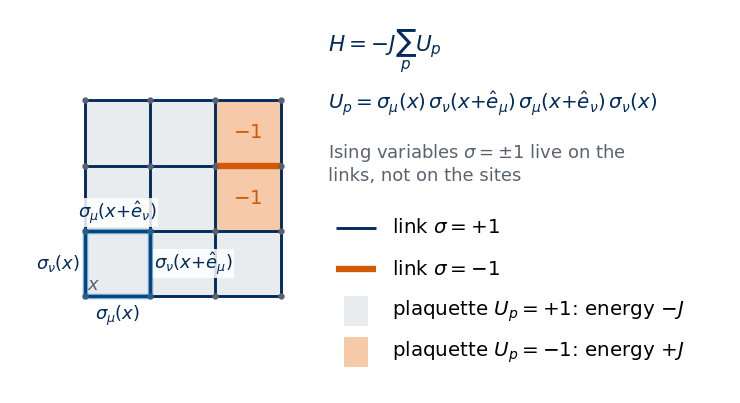

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

# links: sigma = +1 thin navy segment, sigma = -1 thick orange segment (as in the configuration plots of this notebook);
# plaquettes: light grey if U_p = +1, light orange if frustrated (U_p = -1)
def draw_links_2d(ax, U, lw=1.6, shade=True, sites=True):
    # U[mu, x, y]: U[0] horizontal link from (x, y) to (x+1, y), U[1] vertical link from (x, y) to (x, y+1); open patch
    n = U.shape[1]
    if shade:
        for x in range(n - 1):
            for y in range(n - 1):
                Up = U[0, x, y] * U[1, x + 1, y] * U[0, x, y + 1] * U[1, x, y]      # product of the four boundary links
                ax.add_patch(mpatches.Rectangle((x, y), 1, 1, color="#E9ECEF" if Up > 0 else "#F6C9A8", lw=0, zorder=0))
    for mu, (dx, dy) in enumerate([(1, 0), (0, 1)]):
        for x in range(n):
            for y in range(n):
                if x + dx < n and y + dy < n:
                    s = U[mu, x, y]
                    ax.plot([x, x + dx], [y, y + dy], color=NAVY if s > 0 else ORANGE, lw=lw if s > 0 else 2.2 * lw,
                            solid_capstyle="butt", zorder=2 if s > 0 else 3)
    if sites:
        for x in range(n):
            for y in range(n):
                ax.plot(x, y, "o", color=GRAY, ms=2.5, zorder=4)
    ax.set_xlim(-0.3, n - 0.7); ax.set_ylim(-0.3, n - 0.7); ax.set_aspect("equal"); ax.axis("off")

def sketch_gauge_model():
    n = 4                                                           # 4 x 4 sites, open patch
    U = np.ones((2, n, n), int)
    U[0, 2, 2] = -1                                                 # one flipped horizontal link: frustrates the plaquettes above and below
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.03, 0.42, 0.94]); tx = fig.add_axes([0.44, 0.0, 0.56, 1.0]); tx.axis("off")
    draw_links_2d(ax, U, lw=1.6)
    # the plaquette with lower-left corner x = (0, 0) and its four links
    ax.add_patch(mpatches.Rectangle((0, 0), 1, 1, fc="none", ec=BLUE, lw=3, zorder=5, alpha=0.5))
    ax.text(0.5, -0.12, r"$\sigma_\mu(x)$", ha="center", va="top", fontsize=10, color=NAVY)
    ax.text(1.06, 0.5, r"$\sigma_\nu(x{+}\hat e_\mu)$", ha="left", va="center", fontsize=10, color=NAVY,
            bbox=dict(fc="white", ec="none", pad=0.5, alpha=0.85), zorder=6)
    ax.text(0.5, 1.08, r"$\sigma_\mu(x{+}\hat e_\nu)$", ha="center", va="bottom", fontsize=10, color=NAVY,
            bbox=dict(fc="white", ec="none", pad=0.5, alpha=0.85), zorder=6)
    ax.text(-0.08, 0.5, r"$\sigma_\nu(x)$", ha="right", va="center", fontsize=10, color=NAVY)
    ax.text(0.03, 0.03, "$x$", fontsize=10, color=GRAY, ha="left", va="bottom", zorder=6)
    ax.text(2.5, 1.5, "$-1$", ha="center", va="center", fontsize=11, color=ORANGE, zorder=6)
    ax.text(2.5, 2.5, "$-1$", ha="center", va="center", fontsize=11, color=ORANGE, zorder=6)
    ax.set_xlim(-1.1, n - 0.5); ax.set_ylim(-0.6, n - 0.5)

    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.9, r"$H=-J\sum_p U_p$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.76, r"$U_p=\sigma_\mu(x)\,\sigma_\nu(x{+}\hat e_\mu)\,\sigma_\mu(x{+}\hat e_\nu)\,\sigma_\nu(x)$", fontsize=11, color=NAVY, va="center")
    tx.text(0.0, 0.6, "Ising variables $\\sigma=\\pm1$ live on the\nlinks, not on the sites", fontsize=10, color=GRAY, va="center")
    rows = [("link", +1, r"link $\sigma=+1$"), ("link", -1, r"link $\sigma=-1$"),
            ("plaq", +1, r"plaquette $U_p=+1$: energy $-J$"), ("plaq", -1, r"plaquette $U_p=-1$: energy $+J$")]
    for k, (kind, v, label) in enumerate(rows):
        yy = 0.43 - 0.11 * k
        if kind == "link":
            tx.plot([0.02, 0.12], [yy, yy], color=NAVY if v > 0 else ORANGE, lw=1.6 if v > 0 else 3.5, solid_capstyle="butt")
        else:
            tx.add_patch(mpatches.Rectangle((0.04, yy - 0.04), 0.06, 0.08, color="#E9ECEF" if v > 0 else "#F6C9A8", lw=0))
        tx.text(0.16, yy, label, fontsize=11, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_gauge_model()
save_sketch(fig, "sketch_gauge_card.png")
plt.show()


We set $J=k_B=1$ and use the single dimensionless coupling
$$
\beta \equiv \frac{J}{k_BT}.
$$
Large $\beta$ is low temperature. In the lattice-gauge-theory literature this coupling is usually written $\beta$ (or $\beta_g$), and we follow that convention;
it is the analogue of $K=J/k_BT$ of the Ising model (Lab 012). The average of an observable $A$ is $\langle A\rangle=\sum_\sigma A(\sigma)p(\sigma)$.

Throughout the notebook, and in the saved data, a configuration is an array `U` of shape `(d, L, ..., L)` with $d$ spatial axes:
`U[mu][x_0, ..., x_{d-1}]` $=\sigma_\mu(x)$ is the link from site $x$ to $x+\hat e_\mu$. The lattice axis $\mu$ of `U[mu]` is array axis $\mu$, so "the field at $x+\hat e_\mu$"
is `jnp.roll(a, -1, axis=mu)`. Plaquettes are returned with shape `(P, L, ..., L)`, $P=d(d-1)/2$, planes ordered $(0,1)$ in 2D and $(0,1),(0,2),(1,2)$ in 3D;
`plaq[k][x]` is the plaquette whose lower-left corner is $x$.

In [2]:
def shift(a, mu, n=1):
    # the field a (spatial axes only) evaluated at x + n e_mu, periodic boundaries
    return jnp.roll(a, -n, axis=mu)

def plaquettes(U):
    # U: (d, L, ..., L) links  ->  (P, L, ..., L) plaquettes, planes (mu, nu) with mu < nu in lexicographic order
    d = U.shape[0]
    return jnp.stack([U[mu] * shift(U[nu], mu) * shift(U[mu], nu) * U[nu]
                      for mu in range(d) for nu in range(mu + 1, d)])

def energy(U):
    # H = -J sum_p U_p with J = 1
    return -jnp.sum(plaquettes(U))

def energy_2d_loops(U):
    # the same energy for d = 2 with explicit loops over sites: an independent implementation used as a check
    U = np.asarray(U); L = U.shape[1]; E = 0
    for x in range(L):
        for y in range(L):
            E -= U[0, x, y] * U[1, (x + 1) % L, y] * U[0, x, (y + 1) % L] * U[1, x, y]
    return E

rng = np.random.default_rng(0)
U_test = rng.choice([-1, 1], size=(2, 6, 6)).astype(np.float32)        # shape (d, L, L) = (2, 6, 6)
print("links:", U_test.shape, "-> plaquettes:", plaquettes(U_test).shape)
print(f"energy, rolled arrays: {float(energy(U_test)):+.0f}    energy, explicit loops: {energy_2d_loops(U_test):+.0f}")
U3_test = rng.choice([-1, 1], size=(3, 4, 4, 4)).astype(np.float32)      # 3D: (d, L, L, L)
print("3D links:", U3_test.shape, "-> plaquettes:", plaquettes(U3_test).shape, "(3 planes x L^3)")

links: (2, 6, 6) -> plaquettes: (1, 6, 6)
energy, rolled arrays: +4    energy, explicit loops: +4


3D links: (3, 4, 4, 4) -> plaquettes: (3, 4, 4, 4) (3 planes x L^3)


To get a feeling for these objects we draw two configurations of a small 2D lattice. Links are drawn as segments (navy for $\sigma=+1$, orange for $\sigma=-1$); each plaquette is shaded light grey if $U_p=+1$ and
orange if it is frustrated, $U_p=-1$. The left panel is a random configuration (infinite temperature), the right one a configuration with all $\sigma=+1$ except three links.

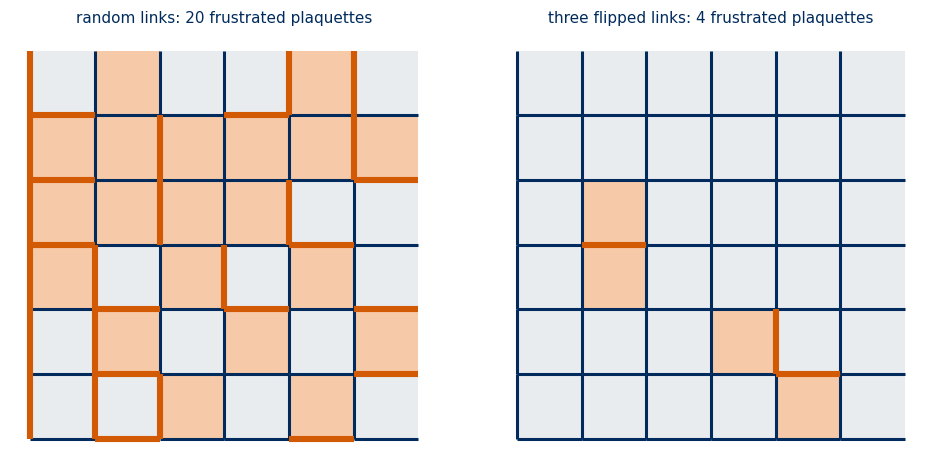

In [3]:
def draw_2d(ax, U, title=""):
    # U: (2, L, L); site (x, y) drawn at (x, y); U[0] horizontal links, U[1] vertical links
    U = np.asarray(U); L = U.shape[1]; P = np.asarray(plaquettes(U))[0]
    for x in range(L):
        for y in range(L):
            ax.add_patch(Rectangle((x, y), 1, 1, color="#E9ECEF" if P[x, y] > 0 else "#F6C9A8", lw=0))
    for sign in (1, -1):                                   # draw the sigma = -1 links last, on top
        for x in range(L):
            for y in range(L):
                for mu, (dx, dy) in enumerate([(1, 0), (0, 1)]):
                    if U[mu, x, y] == sign:
                        ax.plot([x, x + dx], [y, y + dy], color=UJNavy if sign > 0 else DSOrange,
                                lw=2.0 if sign > 0 else 4.0, solid_capstyle="butt", zorder=2 if sign > 0 else 3)
    ax.set_xlim(-0.3, L + 0.3); ax.set_ylim(-0.3, L + 0.3); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=10)

U_few = np.ones((2, 6, 6), np.float32)
U_few[0, 1, 3] = -1                                  # one isolated flipped link
U_few[0, 4, 1] = -1; U_few[1, 4, 1] = -1             # two flipped links meeting at the corner (4, 1) of plaquette (4, 1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.3))
draw_2d(ax[0], U_test, f"random links: {int((np.asarray(plaquettes(U_test)) < 0).sum())} frustrated plaquettes")
draw_2d(ax[1], U_few, f"three flipped links: {int((np.asarray(plaquettes(U_few)) < 0).sum())} frustrated plaquettes")
plt.tight_layout(); plt.show()

In the right panel the isolated flipped horizontal link frustrates the two plaquettes that contain it (above and below). The two flipped links meeting at a corner
lie on one common plaquette, which is flipped twice and therefore satisfied again; only their two other plaquettes are frustrated. Frustrated plaquettes, not flipped links, cost energy.
(The drawing shows the lattice without the periodic wrap-around links of the top row and right column, which are part of the torus.)

### 2.1 Heat-bath Monte Carlo

To sample the Boltzmann distribution with a heat-bath Monte Carlo (MC) algorithm we need the local field of a link. The link $l=(x,\mu)$ belongs to $2(d-1)$ plaquettes: for every direction $\nu\neq\mu$ one "above" ($(x;\mu\nu)$) and one "below" ($(x-\hat e_\nu;\mu\nu)$).
Each of these plaquettes equals $\sigma_l$ times the product of its three other links, a **staple**. Collecting all terms of $H$ that contain $\sigma_l$ gives
$$
\begin{aligned}
H &= -\sigma_l\,h_l + (\text{terms without }\sigma_l),\\
h_l &= \sum_{\nu\neq\mu}\Big[\sigma_\nu(x+\hat e_\mu)\sigma_\mu(x+\hat e_\nu)\sigma_\nu(x)\\
&\qquad\quad + \sigma_\nu(x+\hat e_\mu-\hat e_\nu)\sigma_\mu(x-\hat e_\nu)\sigma_\nu(x-\hat e_\nu)\Big].
\end{aligned}
$$
The staple sum $h_l\in\{-2(d-1),\dots,2(d-1)\}$ plays the role of the local field of the Ising model (Lab 010).

The sketch below shows the staples of a horizontal link $l$ in two dimensions: the three other links of the plaquette above (green) and of the plaquette below (dashed blue). The product of the links of a staple is the value that its plaquette takes when $\sigma_l=+1$, so $h_l$ measures how strongly the surrounding links favour $\sigma_l=+1$. In $d$ dimensions every link has $2(d-1)$ staples, four in 3D.

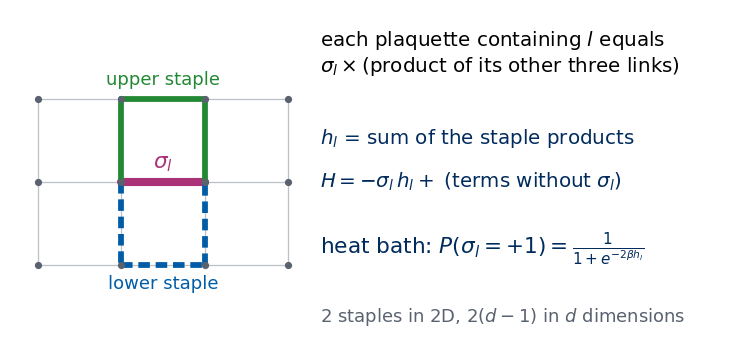

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_staples():
    fig = plt.figure(figsize=(5.5, 2.6))
    ax = fig.add_axes([0.0, 0.0, 0.42, 1.0]); tx = fig.add_axes([0.43, 0.0, 0.57, 1.0]); tx.axis("off")
    for k in range(3):                                              # background lattice, 4 x 3 sites
        ax.plot([0, 3], [k, k], color=GRAY, lw=0.7, alpha=0.4)
    for k in range(4):
        ax.plot([k, k], [0, 2], color=GRAY, lw=0.7, alpha=0.4)
    def seg(p, q, c, lw=3.2, ls="-"):
        ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=ls, solid_capstyle="round")
    # the link l = (x, mu) from (1, 1) to (2, 1)
    seg((1, 1), (2, 1), PURPLE, lw=4.5)
    ax.text(1.5, 1.1, "$\\sigma_l$", ha="center", va="bottom", fontsize=12, color=PURPLE)
    # upper staple: the three other links of the plaquette above l
    for p, q in [((1, 1), (1, 2)), ((1, 2), (2, 2)), ((2, 1), (2, 2))]:
        seg(p, q, GREEN)
    # lower staple: the three other links of the plaquette below l
    for p, q in [((1, 1), (1, 0)), ((1, 0), (2, 0)), ((2, 0), (2, 1))]:
        seg(p, q, BLUE, ls=(0, (2, 1)))
    ax.text(1.5, 2.12, "upper staple", ha="center", va="bottom", fontsize=10, color=GREEN)
    ax.text(1.5, -0.12, "lower staple", ha="center", va="top", fontsize=10, color=BLUE)
    for x in range(4):
        for y in range(3):
            ax.plot(x, y, "o", color=GRAY, ms=3, zorder=4)
    ax.set_xlim(-0.3, 3.3); ax.set_ylim(-0.7, 2.7); ax.set_aspect("equal"); ax.axis("off")

    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.88, "each plaquette containing $l$ equals\n$\\sigma_l\\times$(product of its other three links)", fontsize=11, va="center")
    tx.text(0.0, 0.63, r"$h_l$ = sum of the staple products", fontsize=11, color=NAVY, va="center")
    tx.text(0.0, 0.5, r"$H=-\sigma_l\,h_l+$ (terms without $\sigma_l$)", fontsize=11, color=NAVY, va="center")
    tx.text(0.0, 0.3, r"heat bath: $P(\sigma_l=+1)=\frac{1}{1+e^{-2\beta h_l}}$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.1, "2 staples in 2D, $2(d-1)$ in $d$ dimensions", fontsize=10, color=GRAY, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_staples()
save_sketch(fig, "sketch_gauge_staple.png")
plt.show()


Instead of proposing a flip and accepting it with some probability (Metropolis), the heat-bath algorithm draws the new value of $\sigma_l$ directly from its conditional distribution given all other links:
$$
\begin{aligned}
P(\sigma_l=+1\mid\text{rest}) &= \frac{e^{\beta h_l}}{e^{\beta h_l}+e^{-\beta h_l}}\\
&= \frac{1}{1+e^{-2\beta h_l}}.
\end{aligned}
$$
Sampling exactly from a conditional distribution of $p(\sigma)$ leaves $p(\sigma)$ invariant, so the chain converges to the Boltzmann distribution.

Updating links one at a time would be slow, so we look for links that can be updated simultaneously. Two links interact only if they lie on a common plaquette. Links of different directions can share plaquettes,
so the directions are updated one after the other. Two links of the same direction $\mu$ share a plaquette only if they are displaced by $\pm\hat e_\nu$ with $\nu\neq\mu$.
If we colour the links of direction $\mu$ by the parity of $\sum_{\nu\neq\mu}x_\nu$, such a displacement changes the parity, so all links of one colour are independent given the rest
and can be updated together (this needs even $L$). One **sweep** consists of $2d$ such half-updates, that is, one update of every link.

The implementation follows the JAX idioms of Lab 018: a pure `sweep(U, key, beta)` function with explicit random keys; `lax.scan` repeats sweeps inside one compiled program;
`jax.vmap` runs many independent chains (different $\beta$ and replicas) at once; `jax.jit` compiles everything.
The function `run_gauge` returns int8 links of shape `(n_beta, n_rep * n_samples, d, L, ..., L)`: for each coupling, `n_rep` independent chains each store
`n_samples` configurations separated by `n_between` sweeps after `n_equil` equilibration sweeps. Chains start from the **cold** configuration $\sigma\equiv+1$
(the reason is discussed in Section 5.4).

In [4]:
def staple_sum(U, mu):
    # h_l for all links of direction mu: shape (L, ..., L)
    h = jnp.zeros_like(U[mu])
    for nu in range(U.shape[0]):
        if nu != mu:
            h = h + shift(U[nu], mu) * shift(U[mu], nu) * U[nu]                                   # plaquette (x; mu nu)
            h = h + shift(shift(U[nu], mu), nu, -1) * shift(U[mu], nu, -1) * shift(U[nu], nu, -1)  # plaquette (x - e_nu; mu nu)
    return h

def parity_masks(d, L):
    # masks[mu, c]: links of direction mu whose parity of sum_{nu != mu} x_nu equals c;  shape (d, 2, L, ..., L)
    X = np.indices((L,) * d)
    return jnp.asarray(np.stack([[(X.sum(0) - X[mu]) % 2 == c for c in (0, 1)] for mu in range(d)]))

def sweep(U, key, beta, masks):
    for mu in range(U.shape[0]):
        for c in (0, 1):
            key, sub = jax.random.split(key)
            p_up = jax.nn.sigmoid(2.0 * beta * staple_sum(U, mu))           # heat-bath probability of sigma = +1
            new = jnp.where(jax.random.uniform(sub, p_up.shape) < p_up, 1.0, -1.0)
            U = U.at[mu].set(jnp.where(masks[mu, c], new, U[mu]))
    return U, key

@partial(jax.jit, static_argnames=("n_equil", "n_samples", "n_between"))
def gauge_chains(U0, keys, betas, masks, n_equil, n_samples, n_between):
    # U0: (chains, d, L..), keys: (chains, 2), betas: (chains,) -> int8 samples (chains, n_samples, d, L..)
    def one_chain(U, key, beta):
        step = lambda c, _: (sweep(c[0], c[1], beta, masks), None)
        carry, _ = lax.scan(step, (U, key), None, length=n_equil)
        def store(c, _):
            c, _ = lax.scan(step, c, None, length=n_between)
            return c, c[0].astype(jnp.int8)
        return lax.scan(store, carry, None, length=n_samples)[1]
    return jax.vmap(one_chain)(U0, keys, betas)

def run_gauge(d, L, betas, n_rep, n_equil, n_samples, n_between, seed):
    # every beta gets n_rep independent chains, all started from sigma = +1;  returns (n_beta, n_rep * n_samples, d, L..) int8
    B = jnp.repeat(jnp.asarray(betas, jnp.float32), n_rep)
    U0 = jnp.ones((B.size, d) + (L,) * d, jnp.float32)
    out = gauge_chains(U0, jax.random.split(jax.random.PRNGKey(seed), B.size), B, parity_masks(d, L),
                       n_equil, n_samples, n_between)
    return np.asarray(out).reshape((len(betas), n_rep * n_samples, d) + (L,) * d)

mean_plaq = jax.jit(jax.vmap(lambda U: jnp.mean(plaquettes(U))))      # (batch, d, L..) -> (batch,)  mean plaquette per configuration

<hr/>
## 3. Gauge symmetry

Choose a site $x_0$ and flip **all $2d$ links that touch it**. More generally, choose $g(x)=\pm1$ on every site and set
$$
\sigma_\mu(x)\;\longrightarrow\;\sigma'_\mu(x) = g(x)\,\sigma_\mu(x)\,g(x+\hat e_\mu).
$$
This transformation leaves every plaquette unchanged. Going around a plaquette, every corner $y$ is the end of exactly two of its four links, so $g(y)$ appears twice and $g(y)^2=1$:
$$
\begin{aligned}
U'_{\mu\nu}(x) &= \big[g_1\sigma_\mu(x)g_2\big]\big[g_2\sigma_\nu(x+\hat e_\mu)g_3\big]\big[g_4\sigma_\mu(x+\hat e_\nu)g_3\big]\big[g_1\sigma_\nu(x)g_4\big]\\
&= U_{\mu\nu}(x),
\end{aligned}
$$
with $g_1,\dots,g_4$ the values at the four corners. Every plaquette, hence $H$ and the Boltzmann weight, is unchanged. There are $2^N$ choices of $g$, one independent
$\mathbb Z_2$ symmetry **per site**: this is what makes the symmetry *local*. The global choice $g\equiv-1$ changes no link at all, so $2^{N-1}$ distinct transformations act on the links.

The sketch below shows a gauge transformation at a single site $x_0$, with $g(x_0)=-1$ and $g=+1$ everywhere else. The four links that touch $x_0$ change sign, but every plaquette contains either none or exactly two of them, so no plaquette changes: the frustrated plaquettes (orange) are the same before and after, and so is the energy.

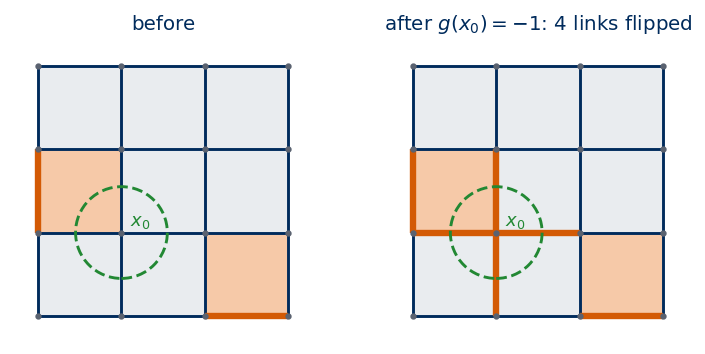

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

# links: sigma = +1 thin navy segment, sigma = -1 thick orange segment (as in the configuration plots of this notebook);
# plaquettes: light grey if U_p = +1, light orange if frustrated (U_p = -1)
def draw_links_2d(ax, U, lw=1.6, shade=True, sites=True):
    # U[mu, x, y]: U[0] horizontal link from (x, y) to (x+1, y), U[1] vertical link from (x, y) to (x, y+1); open patch
    n = U.shape[1]
    if shade:
        for x in range(n - 1):
            for y in range(n - 1):
                Up = U[0, x, y] * U[1, x + 1, y] * U[0, x, y + 1] * U[1, x, y]      # product of the four boundary links
                ax.add_patch(mpatches.Rectangle((x, y), 1, 1, color="#E9ECEF" if Up > 0 else "#F6C9A8", lw=0, zorder=0))
    for mu, (dx, dy) in enumerate([(1, 0), (0, 1)]):
        for x in range(n):
            for y in range(n):
                if x + dx < n and y + dy < n:
                    s = U[mu, x, y]
                    ax.plot([x, x + dx], [y, y + dy], color=NAVY if s > 0 else ORANGE, lw=lw if s > 0 else 2.2 * lw,
                            solid_capstyle="butt", zorder=2 if s > 0 else 3)
    if sites:
        for x in range(n):
            for y in range(n):
                ax.plot(x, y, "o", color=GRAY, ms=2.5, zorder=4)
    ax.set_xlim(-0.3, n - 0.7); ax.set_ylim(-0.3, n - 0.7); ax.set_aspect("equal"); ax.axis("off")

def sketch_gauge_transformation():
    n = 4
    U = np.ones((2, n, n), int)
    U[1, 0, 1] = -1; U[0, 2, 0] = -1                                # two flipped links: four frustrated plaquettes
    x0 = (1, 1)                                                     # site where the gauge transformation g(x0) = -1 acts
    V = U.copy()
    V[0, x0[0], x0[1]] *= -1; V[0, x0[0] - 1, x0[1]] *= -1           # the right and left links of x0
    V[1, x0[0], x0[1]] *= -1; V[1, x0[0], x0[1] - 1] *= -1           # the upper and lower links of x0
    fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.75))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.02, top=0.86, wspace=0.15)
    for ax, W, title in [(axes[0], U, "before"), (axes[1], V, "after $g(x_0)=-1$: 4 links flipped")]:
        draw_links_2d(ax, W, lw=1.6)
        ax.add_patch(mpatches.Circle(x0, 0.55, fc="none", ec=GREEN, lw=1.6, ls="--", zorder=6))
        ax.text(x0[0] + 0.1, x0[1] + 0.08, "$x_0$", fontsize=10, color=GREEN, zorder=7)
        ax.set_title(title, fontsize=11, color=NAVY)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_gauge_transformation()
save_sketch(fig, "sketch_gauge_transformation.png")
plt.show()


Configurations related by a gauge transformation form a **gauge orbit**; they describe the same physical state. Only **gauge-invariant** quantities (the same on the whole orbit)
are physical. The first cell below lets SymPy carry out the cancellation of the corner variables; the second applies a random gauge transformation to random configurations in 2D and 3D
and compares links, plaquettes and energies before and after.

In [5]:
# symbolic check: the plaquette is gauge invariant because every corner variable appears squared
s1, s2, s3, s4 = sp.symbols("sigma_1:5")            # the four links of a plaquette
g1, g2, g3, g4 = sp.symbols("g_1:5")                # the four corner sites
U_p = s1 * s2 * s3 * s4
U_p_transformed = (g1 * s1 * g2) * (g2 * s2 * g3) * (g4 * s3 * g3) * (g1 * s4 * g4)
print("transformed plaquette           :", U_p_transformed)
print("after g_i^2 = 1                  :", U_p_transformed.subs({g ** 2: 1 for g in (g1, g2, g3, g4)}))

transformed plaquette           : g_1**2*g_2**2*g_3**2*g_4**2*sigma_1*sigma_2*sigma_3*sigma_4
after g_i^2 = 1                  : sigma_1*sigma_2*sigma_3*sigma_4


In [6]:
def gauge_transform(U, g):
    # U: (d, L..) links, g: (L..) site variables +-1;  sigma'_mu(x) = g(x) sigma_mu(x) g(x + e_mu)
    return jnp.stack([g * U[mu] * shift(g, mu) for mu in range(U.shape[0])])

for U in (U_test, U3_test):
    d, L = U.shape[0], U.shape[1]
    g = rng.choice([-1, 1], size=(L,) * d).astype(np.float32)
    Ug = gauge_transform(U, g)
    print(f"d = {d}:  fraction of links changed by a random gauge transformation = {float(np.mean(np.asarray(Ug) != U)):.3f};   "
          f"max |U_p' - U_p| = {float(jnp.abs(plaquettes(Ug) - plaquettes(U)).max()):.0f};   E' - E = {float(energy(Ug) - energy(U)):.0f}")

# one site only: exactly the 2d links touching the site change
g_one = np.ones((6, 6), np.float32); g_one[3, 3] = -1
print("single-site transformation in 2D changes", int((np.asarray(gauge_transform(U_test, g_one)) != U_test).sum()), "links")

d = 2:  fraction of links changed by a random gauge transformation = 0.583;   max |U_p' - U_p| = 0;   E' - E = 0


d = 3:  fraction of links changed by a random gauge transformation = 0.438;   max |U_p' - U_p| = 0;   E' - E = 0
single-site transformation in 2D changes 4 links


About half of all links change, the energy does not. A random gauge transformation scrambles the link pattern completely while leaving every plaquette in place.

### 3.1 Counting gauge orbits
On a $3\times3$ torus there are $2\cdot9=18$ links and $2^{18}=262\,144$ configurations, few enough to enumerate. We store each as an 18-bit integer; flipping a link is an exclusive or (XOR) with its bit, and the gauge
transformation at site $x$ is an XOR with the 4-bit mask of the links touching $x$. The group of all transformations is generated by these 9 masks, and the
counting above predicts $2^{N-1}=2^8$ distinct elements and therefore $2^{18}/2^{8}=2^{10}$ orbits. We find the orbit of every configuration by taking the smallest
integer in it as a label.

In [7]:
def link_index(d, L):
    # integer index of link (mu, x): array of shape (d, L, ..., L) with values 0 .. d L^d - 1
    return np.arange(d * L**d).reshape((d,) + (L,) * d)

def site_masks(d, L):
    # bitmask (Python int) of the 2d links touching each site
    idx, masks = link_index(d, L), []
    for x in itertools.product(range(L), repeat=d):
        m = 0
        for mu in range(d):
            xm = list(x); xm[mu] = (xm[mu] - 1) % L
            m |= 1 << int(idx[(mu,) + x]) | 1 << int(idx[(mu,) + tuple(xm)])   # outgoing and incoming link of direction mu
        masks.append(m)
    return masks

def plaquette_masks(d, L):
    # bitmask of the 4 links of every plaquette, in the order of plaquettes(U).ravel()
    idx, masks = link_index(d, L), []
    for mu in range(d):
        for nu in range(mu + 1, d):
            for x in itertools.product(range(L), repeat=d):
                xm, xn = list(x), list(x); xm[mu] = (x[mu] + 1) % L; xn[nu] = (x[nu] + 1) % L
                masks.append(sum(1 << int(i) for i in {idx[(mu,) + x], idx[(nu,) + tuple(xm)], idx[(mu,) + tuple(xn)], idx[(nu,) + x]}))
    return masks

L2, d2 = 3, 2
n_links = d2 * L2**d2
configs = np.arange(2**n_links, dtype=np.int64)                         # all configurations; bit = 1 means sigma = -1
gm = site_masks(d2, L2)
group = {0}
for m in gm:                                                             # all products of site transformations
    group |= {h ^ m for h in group}
group = np.array(sorted(group), dtype=np.int64)
orbit_label = np.full(configs.shape, np.iinfo(np.int64).max)
for h in group:
    orbit_label = np.minimum(orbit_label, configs ^ h)
print(f"3x3 torus: {n_links} links, {configs.size} configurations")
print(f"distinct gauge transformations: {group.size}   (2^(N-1) = {2**(L2*L2-1)})")
print(f"gauge orbits: {np.unique(orbit_label).size}   (2^18 / 2^8 = {2**18 // 2**8})")

3x3 torus: 18 links, 262144 configurations
distinct gauge transformations: 256   (2^(N-1) = 256)
gauge orbits: 1024   (2^18 / 2^8 = 1024)


The enumeration confirms the counting: the 9 site masks generate 256 distinct transformations, and the $2^{18}$ configurations fall into 1024 gauge orbits.

### 3.2 Elitzur's theorem

Elitzur's theorem states that the thermal average of any quantity that is not gauge invariant vanishes. For a single link the proof takes one line. Pick the gauge transformation $g$ that is $-1$ only at the starting site of $l$.
It flips $\sigma_l$, it maps the set of all configurations one-to-one onto itself, and it does not change the weight. Hence
$$
\begin{aligned}
\langle\sigma_l\rangle &= \frac1Z\sum_\sigma\sigma_l\,e^{-\beta H(\sigma)} = \frac1Z\sum_{\sigma}(-\sigma_l)\,e^{-\beta H(\sigma)}\\
&= -\langle\sigma_l\rangle = 0 .
\end{aligned}
$$
For the Ising ferromagnet the same argument with the global flip gives $\langle m\rangle=0$ in every finite system, yet the magnetisation is
spontaneously non-zero below $T_c$: in an infinite system, an infinitesimal field picks one of the two ordered states, and turning the whole lattice around would require a domain
wall whose energy grows with the system size. Elitzur showed that for a **local** symmetry this never happens [S. Elitzur, Phys. Rev. D **12**, 3978 (1975), *Impossibility of spontaneously
breaking local symmetries*]: the transformation that flips $\sigma_l$ changes only the $2d$ links at one site. If a small symmetry-breaking field $h$ coupled to the links, $-h\sum_l\sigma_l$, is added to $H$, this transformation changes the weight
by at most a factor $e^{\pm2d\beta h}$, independently of $L$; the bound survives the infinite-volume limit, so $\langle\sigma_l\rangle\to0$ when $h\to0$ afterwards. Equivalently, the barrier between $\sigma_l=+1$ and $\sigma_l=-1$ stays finite in the infinite system.

The difference between the two kinds of symmetry is visible in the dynamics. We start Monte Carlo from the perfectly "ordered" configuration $\sigma\equiv+1$ and follow the link average $\bar\sigma=\frac1{dN}\sum_l\sigma_l$
and the plaquette average $\bar U=\frac1{N_p}\sum_pU_p$ ($N_p$ = number of plaquettes) along the chain, for a 3D lattice at $\beta=0.9$. Section 5 shows that this coupling lies in the ordered
(deconfined) phase of the 3D model, where the plaquettes stay strongly ordered. For comparison we do the same with the 3D **Ising ferromagnet**, $H_I=-\sum_{\langle ij\rangle}s_is_j$,
at $K=J/k_BT=0.3$, which is in its ordered phase ($K>K_{c}^{I}$, Section 5), starting from $s\equiv+1$, and follow its magnetisation $m$.

72.1 s
L =  6: link average over the last 200 of 10000 sweeps = -0.037   plaquette average = 0.991   |   Ising m = 0.911
L =  8: link average over the last 200 of 10000 sweeps = -0.024   plaquette average = 0.991   |   Ising m = 0.910
L = 10: link average over the last 200 of 10000 sweeps = +0.013   plaquette average = 0.991   |   Ising m = 0.908


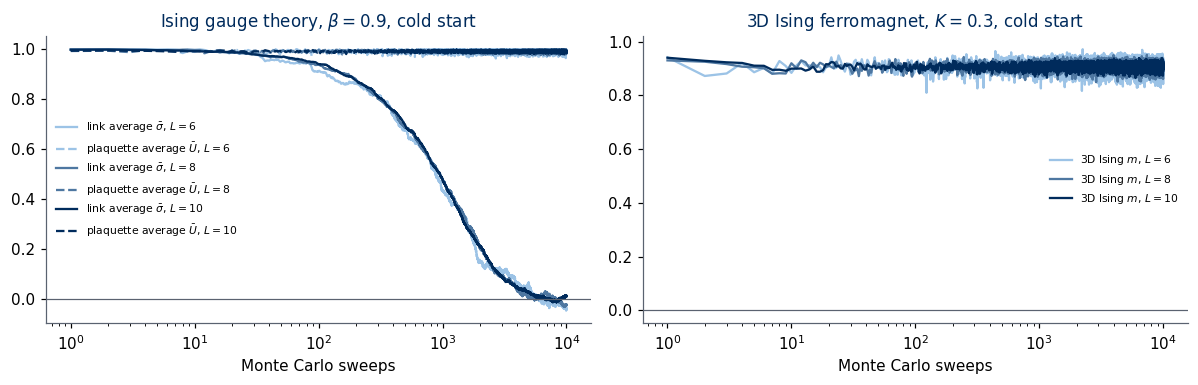

In [8]:
# 3D Ising ferromagnet: heat bath on the two chessboard sublattices; spins s: (L, L, L)
def ising_field(s):
    return sum(jnp.roll(s, k, a) for a in range(3) for k in (1, -1))

def ising_sweep(s, key, K, chess):
    for c in (0, 1):
        key, sub = jax.random.split(key)
        p_up = jax.nn.sigmoid(2.0 * K * ising_field(s))
        new = jnp.where(jax.random.uniform(sub, s.shape) < p_up, 1.0, -1.0)
        s = jnp.where(chess == c, new, s)
    return s, key

def chessboard(L):
    return jnp.asarray(np.indices((L, L, L)).sum(0) % 2)

@partial(jax.jit, static_argnames=("n_sweeps",))
def trace_gauge(U0, key, beta, masks, n_sweeps):
    # links from a cold start: per-sweep link average and plaquette average, shapes (n_sweeps,)
    def step(c, _):
        U, key = sweep(c[0], c[1], beta, masks)
        return (U, key), (jnp.mean(U), jnp.mean(plaquettes(U)))
    return lax.scan(step, (U0, key), None, length=n_sweeps)[1]

@partial(jax.jit, static_argnames=("n_sweeps",))
def trace_ising(s0, key, K, chess, n_sweeps):
    def step(c, _):
        s, key = ising_sweep(c[0], c[1], K, chess)
        return (s, key), jnp.mean(s)
    return lax.scan(step, (s0, key), None, length=n_sweeps)[1]

n_sw, n_tr = 10000, 4                                         # sweeps, independent chains per lattice size
t0 = time.perf_counter()
traces = {}
for L in (6, 8, 10):
    keys = jax.random.split(jax.random.PRNGKey(100 + L), n_tr)
    U0 = jnp.ones((3, L, L, L)); s0 = jnp.ones((L, L, L))
    g_tr = jax.vmap(lambda k: trace_gauge(U0, k, 0.9, parity_masks(3, L), n_sw))(keys)
    i_tr = jax.vmap(lambda k: trace_ising(s0, k, 0.3, chessboard(L), n_sw))(keys)
    traces[L] = [np.asarray(a).mean(0) for a in (*g_tr, i_tr)]          # chain averages: link, plaquette, Ising m
print(f"{time.perf_counter() - t0:.1f} s")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tt = np.arange(1, n_sw + 1)
for i, L in enumerate((6, 8, 10)):
    col = blues(i / 2)
    ax[0].plot(tt, traces[L][0], color=col, lw=1.5, label=fr"link average $\bar\sigma$, $L={L}$")
    ax[0].plot(tt, traces[L][1], color=col, lw=1.5, ls="--", label=fr"plaquette average $\bar U$, $L={L}$")
    ax[1].plot(tt, traces[L][2], color=col, lw=1.5, label=f"3D Ising $m$, $L={L}$")
    print(f"L = {L:2d}: link average over the last 200 of {n_sw} sweeps = {traces[L][0][-200:].mean():+.3f}   plaquette average = {traces[L][1][-200:].mean():.3f}"
          f"   |   Ising m = {traces[L][2][-200:].mean():.3f}")
ax[0].set_xscale("log"); ax[1].set_xscale("log")
ax[0].set_title(r"Ising gauge theory, $\beta=0.9$, cold start"); ax[1].set_title(r"3D Ising ferromagnet, $K=0.3$, cold start")
for a in ax:
    a.set_xlabel("Monte Carlo sweeps"); a.legend(frameon=False, fontsize=7); a.axhline(0, color=UJGray, lw=0.8)
plt.tight_layout(); plt.show()

The link average starts at $1$ and decays to zero on a time scale that does not depend on $L$; over the last 200 of 10 000 sweeps it lies between $-0.037$ and $+0.013$ for $L=6,8,10$.
The "order" of the links is not stable, because it can be undone site by site, through local moves with a finite barrier. The plaquette average, which is gauge invariant, relaxes quickly to a large equilibrium value ($0.991$) and stays there.
The magnetisation of the Ising ferromagnet does not decay (it stays near $0.91$ for all three sizes): undoing it would require a domain wall across the whole lattice. Raw link variables therefore never carry an order
parameter, and the physics of the gauge theory has to be read from gauge-invariant quantities.

<hr/>
## 4. Exact solution in two dimensions

In 2D every plaquette is a "face" of the lattice, and it turns out that the plaquettes behave as **independent** Ising variables. This makes the model solvable in a few lines.
We derive the solution in three steps (gauge fixing, partition function, observables) and check every step.

### 4.1 Gauge fixing
We start with an open lattice of $L\times L$ plaquettes: $(L+1)^2$ sites, $2L(L+1)$ links, no periodic wrap-around.
A gauge transformation can set to $+1$ every link of a **maximal tree**, a set of links that connects all sites without forming a loop: walk from a root site along the tree and
choose $g$ site by site so that each tree link becomes $+1$. A tree on $(L+1)^2$ sites has $(L+1)^2-1$ links, so the number of links left free is
$$
2L(L+1)-(L+1)^2+1 = L^2 = \text{number of plaquettes}.
$$
Adding the free links one at a time in a suitable order, each one closes exactly one new plaquette, so the free links and the plaquettes determine each other one-to-one.
Every gauge orbit contains exactly one tree-fixed configuration, and every orbit has $2^{(L+1)^2-1}$ elements (all transformations except the global one act freely). Therefore
$$
Z_{\rm open} = 2^{(L+1)^2-1}\sum_{\{U_p=\pm1\}}\prod_p e^{\beta U_p} = 2^{(L+1)^2-1}\,(2\cosh\beta)^{L^2}.
$$
With periodic boundaries the torus has $N$ sites, $2N$ links and $N$ plaquettes, and the counting changes in two places.
First, every link lies on exactly two plaquettes, so $\prod_pU_p=\prod_l\sigma_l^2=1$: only $N-1$ plaquettes are independent.
Second, a maximal tree has $N-1$ links, leaving $2N-(N-1)=N+1$ free links: $N-1$ fixed by the plaquettes, plus **two** more, the products of links along a horizontal and a vertical
loop that winds around the torus (*holonomies* $W_x$, $W_y$), which the plaquettes do not determine. The configurations are counted correctly: $2^{N-1}$ (gauge) $\times\,2^{N-1}$ (plaquettes) $\times\,2^2$ (holonomies) $=2^{2N}$.
The sum over plaquettes with the constraint $\prod_pU_p=1$ is done with the projector $\frac12\big(1+\prod_pU_p\big)$:
$$
\begin{aligned}
\sum_{\{U_p\}}\tfrac12\Big(1+\prod_pU_p\Big)\prod_pe^{\beta U_p} &= \tfrac12\Big[(2\cosh\beta)^N + (2\sinh\beta)^N\Big]\\
\Longrightarrow\quad Z_{\rm torus} &= 2^{N-1}\cdot 4\cdot\tfrac12\Big[(2\cosh\beta)^N+(2\sinh\beta)^N\Big]\\
&= 2^N\Big[(2\cosh\beta)^N+(2\sinh\beta)^N\Big].
\end{aligned}
$$
The cell below performs the maximal-tree gauge fixing on a random torus configuration and checks the counting; the next cell checks both formulas for $Z$ against exact enumeration,
symbolically.

In [9]:
def tree_gauge_2d(U):
    # gauge transformation that sets all horizontal links with x < L-1 and the vertical links at x = 0 with y < L-1 to +1
    # (a maximal tree: N - 1 links).  g is built by walking from the root (0, 0) up the column x = 0, then along each row.
    U = np.asarray(U); L = U.shape[1]; g = np.ones((L, L))
    for y in range(1, L):
        g[0, y] = g[0, y - 1] * U[1, 0, y - 1]               # makes sigma'_1(0, y-1) = g(0,y-1) sigma g(0,y) = +1
    for x in range(1, L):
        g[x, :] = g[x - 1, :] * U[0, x - 1, :]               # makes sigma'_0(x-1, y) = +1
    return np.asarray(gauge_transform(U, g.astype(np.float32)))

Uf = tree_gauge_2d(U_test)
L = U_test.shape[1]; N = L * L
tree = np.zeros_like(Uf, bool); tree[0, :L - 1, :] = True; tree[1, 0, :L - 1] = True
print(f"tree links: {tree.sum()} (N - 1 = {N - 1}); all equal to +1 after gauge fixing: {bool(np.all(Uf[tree] == 1))}")
print(f"free links: {(~tree).sum()} = (N - 1) plaquettes + 2 holonomies = {N + 1}")
print(f"plaquettes unchanged by the gauge fixing: {bool(np.array_equal(np.asarray(plaquettes(Uf)), np.asarray(plaquettes(U_test))))}")
print(f"product of all plaquettes on the torus: {float(np.prod(np.asarray(plaquettes(U_test)))):+.0f}")
Wx = lambda U, y: np.prod(np.asarray(U)[0, :, y])            # horizontal non-contractible loop at height y
Wy = lambda U, x: np.prod(np.asarray(U)[1, x, :])            # vertical non-contractible loop at column x
print(f"holonomies W_x(y=0) = {Wx(U_test, 0):+.0f} -> {Wx(Uf, 0):+.0f} after gauge fixing,   W_y(x=0) = {Wy(U_test, 0):+.0f} -> {Wy(Uf, 0):+.0f}")

tree links: 35 (N - 1 = 35); all equal to +1 after gauge fixing: True
free links: 37 = (N - 1) plaquettes + 2 holonomies = 37
plaquettes unchanged by the gauge fixing: True
product of all plaquettes on the torus: +1
holonomies W_x(y=0) = +1 -> +1 after gauge fixing,   W_y(x=0) = +1 -> +1


In [10]:
# exact enumeration: histogram of the number of satisfied minus frustrated plaquettes, then Z(beta) as a SymPy expression
def plaquette_sum_histogram(n_links, pmasks, chunk=2**20):
    # for all 2^n_links configurations (bit = 1: sigma = -1) count n_S = number of configurations with sum_p U_p = S
    pm = np.array(pmasks, dtype=np.int64); n_p = len(pm)
    hist = np.zeros(2 * n_p + 1, dtype=np.int64)
    for start in range(0, 2**n_links, chunk):
        c = np.arange(start, min(start + chunk, 2**n_links), dtype=np.int64)
        frustrated = np.zeros(c.shape, np.int64)
        for m in pm:
            frustrated += np.bitwise_count(c & m) & 1          # U_p = -1 iff an odd number of its links are -1
        hist += np.bincount(n_p - 2 * frustrated + n_p, minlength=2 * n_p + 1)   # index S + n_p
    return hist

def open_lattice_masks(Lp):
    # open lattice of Lp x Lp plaquettes: horizontal links (x, y) x < Lp, y <= Lp and vertical links x <= Lp, y < Lp
    h = {(x, y): i for i, (x, y) in enumerate((x, y) for x in range(Lp) for y in range(Lp + 1))}
    v = {(x, y): len(h) + i for i, (x, y) in enumerate((x, y) for x in range(Lp + 1) for y in range(Lp))}
    masks = [(1 << h[(x, y)]) | (1 << v[(x + 1, y)]) | (1 << h[(x, y + 1)]) | (1 << v[(x, y)]) for x in range(Lp) for y in range(Lp)]
    return len(h) + len(v), masks

b = sp.symbols("beta", positive=True)
def Z_from_hist(hist):
    n_p = (len(hist) - 1) // 2
    return sum(int(n) * sp.exp(b * (S - n_p)) for S, n in enumerate(hist) if n)

t0 = time.perf_counter()
nl, pm = open_lattice_masks(2)
h_open = plaquette_sum_histogram(nl, pm)
Z_open_enum = Z_from_hist(h_open)
Z_open_formula = 2**(9 - 1) * (2 * sp.cosh(b))**4
print(f"open 2x2-plaquette lattice: {nl} links, 9 sites;  Z_enum - 2^8 (2 cosh b)^4 =",
      sp.simplify((Z_open_enum - Z_open_formula).rewrite(sp.exp)))
for L in (2, 3):
    N = L * L
    h_tor = plaquette_sum_histogram(2 * N, plaquette_masks(2, L))
    Z_tor_formula = 2**N * ((2 * sp.cosh(b))**N + (2 * sp.sinh(b))**N)
    print(f"{L}x{L} torus: {2 * N} links;  Z_enum - 2^N[(2cosh b)^N + (2sinh b)^N] =",
          sp.simplify((Z_from_hist(h_tor) - Z_tor_formula).rewrite(sp.exp)))
print(f"({time.perf_counter() - t0:.1f} s)")

open 2x2-plaquette lattice: 12 links, 9 sites;  Z_enum - 2^8 (2 cosh b)^4 = 0
2x2 torus: 8 links;  Z_enum - 2^N[(2cosh b)^N + (2sinh b)^N] = 0


3x3 torus: 18 links;  Z_enum - 2^N[(2cosh b)^N + (2sinh b)^N] = 0
(0.5 s)


Both differences simplify to zero identically in $\beta$: the gauge-fixing argument gives the exact partition function on both geometries.

### 4.2 Thermodynamics
In the thermodynamic limit the term $(2\sinh\beta)^N$ is negligible ($\tanh\beta<1$), and $Z\simeq 2^N(2\cosh\beta)^N$ is the partition function of $N$
**independent** two-state variables with energy $-U_p$. All thermodynamics therefore follows from a single plaquette:
$$
\begin{aligned}
z_1 &= \sum_{U=\pm1}e^{\beta U} = 2\cosh\beta,\\
\langle U_p\rangle &= \frac{\partial\ln z_1}{\partial\beta} = \tanh\beta,\\
c &= \beta^2\frac{\partial^2\ln z_1}{\partial\beta^2} = \frac{\beta^2}{\cosh^2\beta},
\end{aligned}
$$
where $c=\beta^2N_p^{-1}\big(\langle E^2\rangle-\langle E\rangle^2\big)$ is the specific heat per plaquette (as in Lab 012, $c=\partial u/\partial T$ with $u$ the energy per plaquette).
The free energy per plaquette, $f=-T[\ln2+\ln(2\cosh\beta)]$, is an analytic function of $T$ for every $T>0$: **no phase transition**.
These are exactly the formulas of the 1D Ising chain (Lab 012, Section 2.1) with $K\to\beta$: the 2D gauge theory is a 1D Ising chain in disguise, the plaquettes
playing the role of the bond variables $s_is_{i+1}$.

On a finite torus we keep the second term and obtain
$$
\begin{aligned}
\langle U_p\rangle_{L} &= \frac1N\frac{\partial\ln Z_{\rm torus}}{\partial\beta} = \frac{t + t^{N-1}}{1+t^N},\\
t &= \tanh\beta ,
\end{aligned}
$$
where the correction $t^{N-1}$ comes from the global constraint $\prod_pU_p=1$. SymPy checks the single-plaquette formulas and the finite-torus expression below; at $\beta=1$ the
finite-size correction is large for $N=4$ and $9$ and small for $N=16$ ($0.7686$ against $\tanh 1=0.7616$).

In [11]:
# SymPy: single plaquette, and the finite-torus plaquette average
z1 = sp.exp(b) + sp.exp(-b)
U_avg = sp.simplify(sp.diff(sp.log(z1), b))
c_pl = sp.simplify(b**2 * sp.diff(sp.log(z1), b, 2))
print("z_1 =", sp.simplify(z1.rewrite(sp.cosh)), "   <U_p> =", U_avg.rewrite(sp.tanh),
      "   c - beta^2/cosh^2(beta) =", sp.simplify((c_pl - b**2 / sp.cosh(b)**2).rewrite(sp.exp)))

Nsym, t = sp.symbols("N t", positive=True)
Z_tor = 2**Nsym * ((2 * sp.cosh(b))**Nsym + (2 * sp.sinh(b))**Nsym)
U_tor = sp.diff(sp.log(Z_tor), b) / Nsym
U_tor_t = (t + t**(Nsym - 1)) / (1 + t**Nsym)
for Nv in (4, 9, 16):
    exact_t = sp.simplify((U_tor.subs(Nsym, Nv) - U_tor_t.subs({Nsym: Nv, t: sp.tanh(b)})).rewrite(sp.exp))
    lhs = float(U_tor.subs({Nsym: Nv, b: 1.0}))
    print(f"N = {Nv:2d}: (1/N) d ln Z/d beta - (t + t^(N-1))/(1 + t^N) = {exact_t};   at beta = 1: {lhs:.10f}, tanh(1) = {np.tanh(1.0):.10f}")

z_1 =

 2*cosh(beta)    <U_p> = tanh(beta)    c - beta^2/cosh^2(beta) = 0
N =  4: (1/N) d ln Z/d beta - (t + t^(N-1))/(1 + t^N) = 0;   at beta = 1: 0.9004126814, tanh(1) = 0.7615941560


N =  9: (1/N) d ln Z/d beta - (t + t^(N-1))/(1 + t^N) = 0;   at beta = 1: 0.8053565803, tanh(1) = 0.7615941560
N = 16: (1/N) d ln Z/d beta - (t + t^(N-1))/(1 + t^N) = 0;   at beta = 1: 0.7685692242, tanh(1) = 0.7615941560


### 4.3 Monte Carlo and the 2D data set

We now generate (or load) the 2D Monte Carlo data set and compare the measured $\langle U_p\rangle$ and $c$ with the exact results. First we check the sampler itself
on the $4\times4$ torus, against the exact finite-size formula $\langle U_p\rangle_L$.

One detail concerns the stored configurations. Local Monte Carlo moves change the gauge orbit only slowly at large $\beta$ (Section 3.2), so a chain started from $\sigma\equiv+1$
would keep an artificial excess of positive links. Since the Boltzmann weight is gauge invariant, applying an independent uniformly random gauge transformation $g$ to every stored
configuration produces an exact sample of the same distribution with the gauge degrees of freedom fully equilibrated. All saved configurations are gauge-randomised in this way.

In [12]:
def gauge_randomise(U, d, seed):
    # U: (batch..., d, L, ..., L) int8 links;  sigma'_mu(x) = g(x) sigma_mu(x) g(x + e_mu) with random g per configuration
    r = np.random.default_rng(seed)
    lat = U.shape[-d:]
    g = r.choice(np.array([-1, 1], np.int8), size=U.shape[:-d - 1] + lat)
    out = np.empty_like(U)
    for mu in range(d):
        idx = (Ellipsis, mu) + (slice(None),) * d                      # selects sigma_mu for every configuration
        out[idx] = g * U[idx] * np.roll(g, -1, axis=g.ndim - d + mu)
    return out

# sampler check on the 4x4 torus (N = 16 plaquettes) against (t + t^15) / (1 + t^16)
betas_chk = [0.3, 0.7, 1.2, 2.0]
t0 = time.perf_counter()
smp = run_gauge(2, 4, betas_chk, n_rep=64, n_equil=200, n_samples=200, n_between=2, seed=7)       # (4, 12800, 2, 4, 4)
for i, bv in enumerate(betas_chk):
    up = np.asarray(mean_plaq(jnp.asarray(smp[i], jnp.float32))).reshape(64, 200).mean(1)        # one mean per chain
    tv = np.tanh(bv); exact = (tv + tv**15) / (1 + tv**16)
    print(f"beta = {bv:.1f}:  <U_p> MC = {up.mean():.4f} +- {up.std(ddof=1) / np.sqrt(len(up)):.4f}   exact 4x4 torus = {exact:.4f}")
print(f"({time.perf_counter() - t0:.1f} s)")

# gauge randomisation: plaquettes unchanged, links scrambled
smp_g = gauge_randomise(smp[3, :100], 2, seed=1)
print("gauge randomisation keeps every plaquette:", bool(np.array_equal(np.asarray(jax.vmap(plaquettes)(jnp.asarray(smp_g, jnp.float32))),
                                                                  np.asarray(jax.vmap(plaquettes)(jnp.asarray(smp[3, :100], jnp.float32))))),
      f";  link average before {smp[3, :100].mean():+.3f}, after {smp_g.mean():+.3f}")

beta = 0.3:  <U_p> MC = 0.2949 +- 0.0024   exact 4x4 torus = 0.2913
beta = 0.7:  <U_p> MC = 0.6047 +- 0.0016   exact 4x4 torus = 0.6047
beta = 1.2:  <U_p> MC = 0.8534 +- 0.0018   exact 4x4 torus = 0.8525
beta = 2.0:  <U_p> MC = 0.9902 +- 0.0006   exact 4x4 torus = 0.9902
(3.8 s)


gauge randomisation keeps every plaquette: True ;  link average before +0.127, after -0.016


The sampler reproduces the exact finite-torus values within its error bars (the largest difference, at $\beta=0.3$, is $0.0036$, or 1.5 error bars), and the gauge randomisation leaves every plaquette in place while removing the excess of positive links (link average $+0.127$ before, $-0.016$ after).

The 2D data set is stored with one file per lattice size and the following keys.

| key | shape / type | meaning |
|---|---|---|
| `links` | `(n_beta, n_samples, 2, L, L)`, int8 $\pm1$ | `links[i, k, mu, x, y]` $=\sigma_\mu(x,y)$, link from $(x,y)$ to $(x,y)+\hat e_\mu$; $\mu=0$: $x$-direction, $\mu=1$: $y$-direction; periodic |
| `beta` | `(n_beta,)`, float | couplings $\beta=J/k_BT$ ($J=k_B=1$) |
| `T` | `(n_beta,)`, float | temperatures $T=1/\beta$ |
| `chain` | `(n_samples,)`, int | index of the independent Markov chain each sample comes from (for error bars) |
| `L`, `d`, `n_rep`, `n_equil`, `n_between`, `seed` | int | lattice size, dimension, chains per $\beta$, equilibration sweeps, sweeps between stored samples, random seed |
| `sampler`, `layout` | str | description of the algorithm and of the array layout |

The couplings span $\beta\in[0.1,\,2.4]$ in steps of $0.1$; the 2D model has no transition, so the grid is uniform.

In [13]:
LAYOUT = ("links[i_beta, i_sample, mu, x_0, ..., x_{d-1}] = sigma_mu(x): Ising link variable (+-1, int8) on the link from site x "
          "to x + e_mu, periodic L^d lattice; mu = 0..d-1 is the lattice direction = array axis of x_mu. Plaquette U_{mu nu}(x) = "
          "sigma_mu(x) sigma_nu(x+e_mu) sigma_mu(x+e_nu) sigma_nu(x); H = -J sum_p U_p, J = 1, beta = J / (k_B T).")
SAMPLER = ("heat-bath Monte Carlo on links (checkerboard per direction), cold start sigma = +1, n_rep independent chains per beta; "
           "every stored configuration is gauge-randomised by an independent uniformly random gauge transformation g(x) = +-1.")

def make_dataset(d, L, betas, n_rep, n_equil, n_samples, n_between, seed):
    path = f"{DATA}/z2gauge_{d}d_L{L}.npz"
    if os.path.exists(path):
        ds = dict(np.load(path))
        print(f"loaded {d}D, L = {L}: links {ds['links'].shape}")
        return ds
    t0 = time.perf_counter()
    links = run_gauge(d, L, betas, n_rep, n_equil, n_samples, n_between, seed)
    links = gauge_randomise(links, d, seed + 1).astype(np.int8)
    ds = dict(links=links, beta=np.asarray(betas, float), T=1.0 / np.asarray(betas, float),
              chain=np.repeat(np.arange(n_rep), n_samples), L=L, d=d, n_rep=n_rep, n_equil=n_equil,
              n_between=n_between, seed=seed, sampler=SAMPLER, layout=LAYOUT)
    np.savez_compressed(path, **ds)
    print(f"generated and saved {d}D, L = {L}: links {links.shape}, {time.perf_counter() - t0:.1f} s, "
          f"{os.path.getsize(path) / 2**20:.1f} MB")
    return ds

BETAS_2D = np.round(np.arange(0.1, 2.41, 0.1), 2)
ds2 = {L: make_dataset(2, L, BETAS_2D, n_rep=16, n_equil=500, n_samples=32, n_between=4, seed=2000 + L) for L in (16, 32)}

generated and saved 2D, L = 16: links (24, 512, 2, 16, 16), 10.3 s, 1.0 MB


generated and saved 2D, L = 32: links (24, 512, 2, 32, 32), 25.9 s, 3.8 MB


From each configuration we compute the plaquette average $\bar U=\frac1{N_p}\sum_pU_p$. Its mean gives $\langle U_p\rangle=\langle\bar U\rangle$, and its fluctuations give the specific heat,
$c=\beta^2N_p\big(\langle\bar U^2\rangle-\langle\bar U\rangle^2\big)$. Error bars are standard errors of the mean over the independent chains.

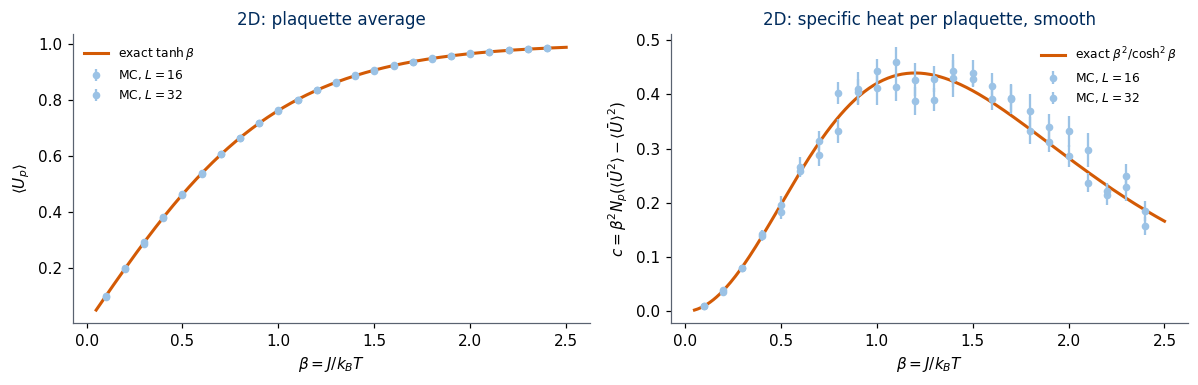

L = 32: max |<U_p>_MC - tanh beta| = 0.00200;  max deviation in units of the error bar = 1.89
L = 32: max |c_MC - beta^2/cosh^2 beta| / error = 2.15
link average over the whole L = 32 data set (Elitzur): +0.00021


In [14]:
def per_chain(values, chain):
    # values: (n_samples,), chain: (n_samples,) -> per-chain means (n_rep,)
    return np.array([values[chain == k].mean() for k in np.unique(chain)])

def plaquette_stats(ds):
    # <U_p> and c with errors from the spread over chains;  returns arrays of shape (n_beta,)
    d, L = int(ds["d"]), int(ds["L"]); n_p = d * (d - 1) // 2 * L**d
    out = {k: [] for k in ("U", "dU", "c", "dc")}
    for i, bv in enumerate(ds["beta"]):
        ub = np.asarray(mean_plaq(jnp.asarray(ds["links"][i], jnp.float32)))
        cu = per_chain(ub, ds["chain"])
        cc = np.array([bv**2 * n_p * ub[ds["chain"] == k].var() for k in np.unique(ds["chain"])])
        out["U"].append(ub.mean()); out["dU"].append(cu.std(ddof=1) / np.sqrt(len(cu)))
        out["c"].append(bv**2 * n_p * ub.var()); out["dc"].append(cc.std(ddof=1) / np.sqrt(len(cc)))
    return {k: np.array(v) for k, v in out.items()}

st2 = {L: plaquette_stats(ds2[L]) for L in ds2}
bf = np.linspace(0.05, 2.5, 300)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(bf, np.tanh(bf), color=DSOrange, lw=2, label=r"exact $\tanh\beta$")
ax[1].plot(bf, bf**2 / np.cosh(bf)**2, color=DSOrange, lw=2, label=r"exact $\beta^2/\cosh^2\beta$")
for i, L in enumerate(st2):
    ax[0].errorbar(BETAS_2D, st2[L]["U"], st2[L]["dU"], fmt="o", ms=4, color=blues(i), label=f"MC, $L={L}$")
    ax[1].errorbar(BETAS_2D, st2[L]["c"], st2[L]["dc"], fmt="o", ms=4, color=blues(i), label=f"MC, $L={L}$")
ax[0].set_ylabel(r"$\langle U_p\rangle$"); ax[1].set_ylabel(r"$c=\beta^2N_p(\langle\bar U^2\rangle-\langle\bar U\rangle^2)$")
ax[0].set_title("2D: plaquette average"); ax[1].set_title("2D: specific heat per plaquette, smooth")
for a in ax: a.set_xlabel(r"$\beta=J/k_BT$"); a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

L = 32
dev = (st2[L]["U"] - np.tanh(BETAS_2D)) / st2[L]["dU"]
print(f"L = {L}: max |<U_p>_MC - tanh beta| = {np.abs(st2[L]['U'] - np.tanh(BETAS_2D)).max():.5f};  "
      f"max deviation in units of the error bar = {np.abs(dev).max():.2f}")
dev_c = (st2[L]["c"] - BETAS_2D**2 / np.cosh(BETAS_2D)**2) / st2[L]["dc"]
print(f"L = {L}: max |c_MC - beta^2/cosh^2 beta| / error = {np.abs(dev_c).max():.2f}")
print(f"link average over the whole L = {L} data set (Elitzur): {ds2[L]['links'].mean():+.5f}")

The Monte Carlo data follow the exact solution. On the $L=32$ lattice the largest deviation of $\langle U_p\rangle$ from $\tanh\beta$ is $0.002$, at most $1.9$ error bars, the specific heat stays within $2.15$ error bars of $\beta^2/\cosh^2\beta$, and the link average over the whole data set is $0.0002$, as Elitzur's theorem requires.

The exact solution rests on the independence of the plaquettes, and this can be checked directly. If the plaquettes are independent, the connected correlation of two different plaquettes vanishes,
$\langle U_pU_{p'}\rangle-\langle U_p\rangle\langle U_{p'}\rangle=0$, and the number of frustrated plaquettes is binomially distributed with probability $q=(1-\tanh\beta)/2$
per plaquette. We measure the correlation for nearest-neighbour and diagonal plaquettes.

In [15]:
L = 32
print(" beta   <U_p U_p'>_c (neighbour)   <U_p U_p'>_c (diagonal)   frustrated fraction   (1 - tanh beta)/2")
for bv in (0.3, 0.8, 1.5):
    i = int(np.argmin(np.abs(BETAS_2D - bv)))
    P = np.asarray(jax.vmap(plaquettes)(jnp.asarray(ds2[L]["links"][i], jnp.float32)))[:, 0]    # (samples, L, L)
    m = P.mean()
    c_nn = (P * np.roll(P, 1, axis=1)).mean() - m**2
    c_dg = (P * np.roll(np.roll(P, 1, axis=1), 1, axis=2)).mean() - m**2
    print(f" {bv:.1f}        {c_nn:+.5f}                  {c_dg:+.5f}                 {(P < 0).mean():.4f}             {(1 - np.tanh(bv)) / 2:.4f}")

 beta   <U_p U_p'>_c (neighbour)   <U_p U_p'>_c (diagonal)   frustrated fraction   (1 - tanh beta)/2


 0.3        +0.00041                  +0.00138                 0.3540             0.3543
 0.8        -0.00037                  +0.00016                 0.1680             0.1680
 1.5        +0.00050                  -0.00051                 0.0473             0.0474


### 4.4 Wilson loops
For a closed path $C$ on the lattice the **Wilson loop** is the product of the links along it, $W(C)=\big\langle\prod_{l\in C}\sigma_l\big\rangle$.
It is gauge invariant, since every site of a closed path is the end of exactly two of its links. (A product along an **open** path is not invariant, since its end points appear once;
by the argument of Section 3.2 its average is zero, see Exercise 1.) For an $R\times T$ rectangle we write $W(R,T)$.

Wilson loops are related to plaquettes by a lattice version of Stokes' theorem. For a contractible loop, the product of links along $C$ equals the product of the plaquettes of any surface $A$ bounded by $C$:
$$
\prod_{l\in C}\sigma_l = \prod_{p\in A}U_p .
$$
The proof is one observation: in the product of plaquettes, every link inside $A$ belongs to two plaquettes of $A$ and appears squared, so only the boundary links remain.

The sketch below shows a rectangular loop $\mathcal C$ of $R=4$ by $T=2$ lattice spacings. The product of the links along it equals the product of the eight plaquettes $U_p$ of the enclosed area $A$, because each interior link belongs to two of these plaquettes and drops out. How the average of this product decreases with the size of the loop, with its area or only with its perimeter, distinguishes the two phases of the gauge theory.

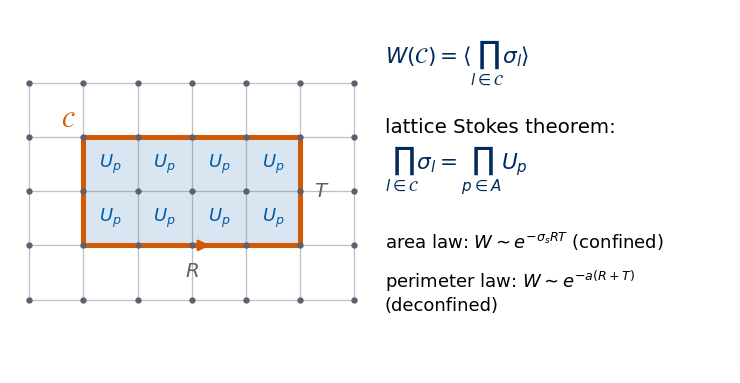

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_wilson_loop():
    nx, ny = 7, 5
    x0, y0, R, Tt = 1, 1, 4, 2                                      # an R x T rectangle with lower-left corner (x0, y0)
    fig = plt.figure(figsize=(5.5, 2.75))
    ax = fig.add_axes([0.0, 0.0, 0.5, 1.0]); tx = fig.add_axes([0.52, 0.0, 0.48, 1.0]); tx.axis("off")
    for k in range(ny):
        ax.plot([0, nx - 1], [k, k], color=GRAY, lw=0.7, alpha=0.4)
    for k in range(nx):
        ax.plot([k, k], [0, ny - 1], color=GRAY, lw=0.7, alpha=0.4)
    ax.add_patch(mpatches.Rectangle((x0, y0), R, Tt, fc=BLUE, alpha=0.15, lw=0))      # the enclosed area A
    for i in range(R):
        for j in range(Tt):
            ax.text(x0 + i + 0.5, y0 + j + 0.5, "$U_p$", ha="center", va="center", fontsize=10, color=BLUE)
    corners = np.array([(x0, y0), (x0 + R, y0), (x0 + R, y0 + Tt), (x0, y0 + Tt), (x0, y0)])
    ax.plot(corners[:, 0], corners[:, 1], color=ORANGE, lw=2.8, solid_joinstyle="round")
    ax.annotate("", xy=(x0 + 2.4, y0), xytext=(x0 + 1.6, y0), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.6, mutation_scale=12))
    ax.text(x0 + R / 2, y0 - 0.3, "$R$", ha="center", va="top", fontsize=11, color=GRAY)
    ax.text(x0 + R + 0.25, y0 + Tt / 2, "$T$", ha="left", va="center", fontsize=11, color=GRAY)
    ax.text(x0 - 0.15, y0 + Tt + 0.2, r"$\mathcal{C}$", fontsize=12, color=ORANGE, ha="right")
    for x in range(nx):
        for y in range(ny):
            ax.plot(x, y, "o", color=GRAY, ms=2.5, zorder=4)
    ax.set_xlim(-0.3, nx - 0.7); ax.set_ylim(-0.5, ny - 0.5); ax.set_aspect("equal"); ax.axis("off")

    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.86, r"$W(\mathcal{C})=\langle\prod_{l\in\mathcal{C}}\sigma_l\rangle$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.68, "lattice Stokes theorem:", fontsize=11, va="center")
    tx.text(0.0, 0.56, r"$\prod_{l\in\mathcal{C}}\sigma_l=\prod_{p\in A}U_p$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.36, "area law: $W\\sim e^{-\\sigma_s RT}$ (confined)", fontsize=10, va="center")
    tx.text(0.0, 0.22, "perimeter law: $W\\sim e^{-a(R+T)}$\n(deconfined)", fontsize=10, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_wilson_loop()
save_sketch(fig, "sketch_gauge_wilson_loop.png")
plt.show()


With independent plaquettes (open lattice, or the torus for $N\to\infty$) the Wilson loop therefore obeys an **area law**:
$$
W(R,T) = \prod_{p\in A}\langle U_p\rangle = (\tanh\beta)^{RT} = e^{-\sigma_s\,RT},\qquad \sigma_s = -\ln\tanh\beta>0 .
$$
On the finite torus the same projector trick as in Section 4.1 gives, with $|A|$ plaquettes inside the loop,
$$
\begin{aligned}
W_L(A) &= \frac{(2\sinh\beta)^{|A|}(2\cosh\beta)^{N-|A|} + (2\cosh\beta)^{|A|}(2\sinh\beta)^{N-|A|}}{(2\cosh\beta)^N+(2\sinh\beta)^N}\\
&= \frac{t^{|A|}+t^{N-|A|}}{1+t^N}.
\end{aligned}
$$
The physical meaning of the area law comes from lattice gauge theory, where one lattice direction is (imaginary) time. A rectangle of spatial extent $R$ and temporal extent $T$ describes
a pair of static external charges created at distance $R$, held for a time $T$ and annihilated; for large $T$, $W(R,T)\sim e^{-V(R)T}$ with $V(R)$ the energy of the pair
[Wilson 1974; Kogut 1979]. The area law gives $V(R)=\sigma_sR$: the energy grows linearly with the separation, and the charges can never be pulled apart. This is **confinement**,
and the coefficient $\sigma_s$ is the **string tension**. In 2D, $\sigma_s>0$ at every finite $\beta$: the theory confines at every temperature.

The cell below checks Stokes' theorem on random loops, and the torus formula symbolically and by exact enumeration on the $3\times3$ torus.

In [16]:
# Stokes theorem on random configurations, and the torus Wilson-loop formula symbolically and by exact enumeration
def rect_loop(U, x, y, R, T):
    # product of links around the R x T rectangle with lower-left corner (x, y) in the plane (0, 1); U: (2, L, L) numpy
    L = U.shape[1]; p = 1
    for k in range(R): p *= U[0, (x + k) % L, y] * U[0, (x + k) % L, (y + T) % L]
    for k in range(T): p *= U[1, x, (y + k) % L] * U[1, (x + R) % L, (y + k) % L]
    return p

ok = True
for trial in range(200):
    Ur = rng.choice([-1, 1], size=(2, 8, 8)); P = np.asarray(plaquettes(Ur))[0]
    x, y, R, T = rng.integers(0, 8), rng.integers(0, 8), rng.integers(1, 6), rng.integers(1, 6)
    inside = np.prod([P[(x + i) % 8, (y + j) % 8] for i in range(R) for j in range(T)])
    ok &= rect_loop(Ur, x, y, R, T) == inside
print("lattice Stokes theorem holds on 200 random loops:", bool(ok))

A, Nn = sp.symbols("A N", positive=True, integer=True)
ch, sh = 2 * sp.cosh(b), 2 * sp.sinh(b)
W_proj = (sh**A * ch**(Nn - A) + ch**A * sh**(Nn - A)) / (ch**Nn + sh**Nn)
W_t = (t**A + t**(Nn - A)) / (1 + t**Nn)
diff = sp.simplify(sp.powsimp(sp.expand_power_base((W_proj.subs(sp.sinh(b), t * sp.cosh(b))), force=True), force=True) - W_t)
print("projector formula minus (t^A + t^(N-A))/(1 + t^N), with sinh = t cosh:", diff)

# exact enumeration on the 3x3 torus: W(1,1), W(1,2), W(2,2) at beta = 0.7 by summing over all 2^18 configurations
L, N, bv = 3, 9, 0.7
bits = ((configs[:, None] >> np.arange(18)) & 1).astype(np.int8)
Uall = (1 - 2 * bits).reshape(-1, 2, L, L)
w = np.exp(bv * np.asarray(jax.vmap(lambda U: jnp.sum(plaquettes(U)))(jnp.asarray(Uall, jnp.float32)), dtype=np.float64))
for R, T in ((1, 1), (1, 2), (2, 2)):
    loop = np.prod(np.concatenate([Uall[:, 0, :R, 0], Uall[:, 0, :R, T], Uall[:, 1, 0, :T], Uall[:, 1, R, :T]], axis=1), axis=1)
    tv = np.tanh(bv)
    print(f"3x3 torus, beta = {bv}: W({R},{T}) enumeration = {(w * loop).sum() / w.sum():.12f}   "
          f"(t^A + t^(N-A))/(1+t^N) = {(tv**(R*T) + tv**(N - R*T)) / (1 + tv**N):.12f}")

lattice Stokes theorem holds on 200 random loops: True
projector formula minus (t^A + t^(N-A))/(1 + t^N), with sinh = t cosh: 0


3x3 torus, beta = 0.7: W(1,1) enumeration = 0.615545646226   (t^A + t^(N-A))/(1+t^N) = 0.615545646226
3x3 torus, beta = 0.7: W(1,2) enumeration = 0.390511097994   (t^A + t^(N-A))/(1+t^N) = 0.390511097994
3x3 torus, beta = 0.7: W(2,2) enumeration = 0.211768889423   (t^A + t^(N-A))/(1+t^N) = 0.211768889423


Stokes' theorem holds on all 200 random loops, and the torus formula reproduces the enumerated Wilson loops to all printed digits.

We now measure Wilson loops in the Monte Carlo data. For square loops $R\times R$ we average the loop product over all positions and both orientations of every configuration.
The plot shows $W(R,R)$ against the area $A=R^2$ on a logarithmic axis; the lines are $(\tanh\beta)^{A}$.

beta = 0.5: W(R,R) for R = 1..6: 0.4614  0.0466  0.0018  0.0009  0.0006  0.0016   |  tanh(beta)^(R^2): 0.4621  0.0456  0.0010  0.0000  0.0000  0.0000
beta = 0.8: W(R,R) for R = 1..6: 0.6641  0.1919  0.0243  -0.0019  0.0008  -0.0004   |  tanh(beta)^(R^2): 0.6640  0.1944  0.0251  0.0014  0.0000  0.0000
beta = 1.2: W(R,R) for R = 1..6: 0.8344  0.4856  0.1978  0.0554  0.0089  0.0005   |  tanh(beta)^(R^2): 0.8337  0.4830  0.1945  0.0544  0.0106  0.0014


beta = 1.6: W(R,R) for R = 1..6: 0.9218  0.7218  0.4832  0.2767  0.1350  0.0543   |  tanh(beta)^(R^2): 0.9217  0.7216  0.4799  0.2711  0.1301  0.0531
beta = 2.0: W(R,R) for R = 1..6: 0.9640  0.8635  0.7193  0.5576  0.4031  0.2720   |  tanh(beta)^(R^2): 0.9640  0.8637  0.7191  0.5565  0.4002  0.2674


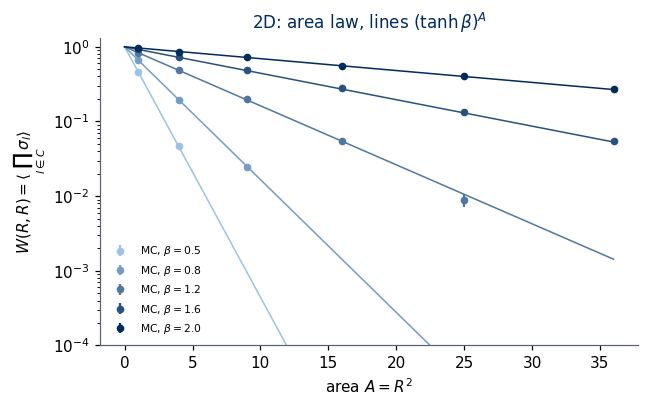

In [17]:
def line_prod(a, mu, n):
    # product of n consecutive links of direction mu starting at x:  a = U[mu], shape (L..)
    out = jnp.ones_like(a)
    for k in range(n):
        out = out * shift(a, mu, k)
    return out

def wilson_loop(U, R, T):
    # average of the R x T loop product over positions and all ordered planes (mu, nu): R along mu, T along nu
    d, vals = U.shape[0], []
    for mu in range(d):
        for nu in range(d):
            if mu != nu:
                a, c = line_prod(U[mu], mu, R), line_prod(U[nu], nu, T)
                vals.append(jnp.mean(a * shift(c, mu, R) * shift(a, nu, T) * c))
    return jnp.mean(jnp.stack(vals))

_wilson_fns = {}
def wilson_table(links, Rmax, batch=256):
    # links: (n_samples, d, L..) int8 -> W[R-1, T-1] per sample, shape (n_samples, Rmax, Rmax); one compiled function per Rmax
    if Rmax not in _wilson_fns:
        _wilson_fns[Rmax] = jax.jit(jax.vmap(lambda U: jnp.stack([jnp.stack([wilson_loop(U, R, T) for T in range(1, Rmax + 1)])
                                                                  for R in range(1, Rmax + 1)])))
    f = _wilson_fns[Rmax]
    return np.concatenate([np.asarray(f(jnp.asarray(links[k:k + batch], jnp.float32))) for k in range(0, len(links), batch)])

L = 32
fig, ax = plt.subplots(figsize=(6, 3.8))
for j, bv in enumerate((0.5, 0.8, 1.2, 1.6, 2.0)):
    i = int(np.argmin(np.abs(BETAS_2D - bv)))
    Wt = wilson_table(ds2[L]["links"][i], 6)
    WRR = np.array([Wt[:, R - 1, R - 1].mean() for R in range(1, 7)])
    eRR = np.array([per_chain(Wt[:, R - 1, R - 1], ds2[L]["chain"]).std(ddof=1) / np.sqrt(int(ds2[L]["n_rep"])) for R in range(1, 7)])
    keep = WRR > 3 * eRR                                        # plot only loops measured with significance
    Ar = np.arange(1, 7)**2
    col = blues(j / 4)
    ax.errorbar(Ar[keep], WRR[keep], eRR[keep], fmt="o", ms=4, color=col, label=fr"MC, $\beta={bv}$")
    Af = np.arange(0, 37); ax.plot(Af, np.tanh(bv)**Af, color=col, lw=1)
    print(f"beta = {bv}: W(R,R) for R = 1..6: " + "  ".join(f"{v:.4f}" for v in WRR) +
          f"   |  tanh(beta)^(R^2): " + "  ".join(f"{np.tanh(bv)**(R*R):.4f}" for R in range(1, 7)))
ax.set_yscale("log"); ax.set_ylim(1e-4, 1.3); ax.set_xlabel("area $A=R^2$"); ax.set_ylabel(r"$W(R,R)=\langle\prod_{l\in C}\sigma_l\rangle$")
ax.set_title(r"2D: area law, lines $(\tanh\beta)^A$"); ax.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

In 2D the Wilson loop decays exponentially with the **area** at every coupling, with string tension $\sigma_s=-\ln\tanh\beta$ that is small at low $T$ but
never zero; a straight line on this logarithmic plot is the area law. At $\beta=2.0$, for example, the measured $W(6,6)=0.272$ compares with $(\tanh\beta)^{36}=0.267$, while at small $\beta$
the large loops fall below the statistical noise of the data.

### 4.5 Topological sectors
The energy is minimal, $E_0=-N_p$, when every plaquette is satisfied, $U_p=+1$. On an open lattice this fixes the configuration up to a gauge transformation: one gauge orbit.
On the torus the plaquettes do not fix the two holonomies $W_x=\prod_{x}\sigma_0(x,y)$ and $W_y=\prod_y\sigma_1(x,y)$ (Section 4.1). In a ground state, $W_x$ does not depend on the
row $y$ where it is measured (two rows bound a strip of plaquettes, and by the Stokes argument their ratio is the product of these plaquettes, $=+1$), and it is gauge invariant.
Hence the ground states split into $2^2=4$ gauge-inequivalent **topological sectors** $(W_x,W_y)\in\{\pm1\}^2$, each a gauge orbit of $2^{N-1}$ configurations:
$$
\begin{aligned}
\#\{\text{ground states}\} &= 4\cdot 2^{N-1} = 2^{N+1}\ \text{configurations},\\
&\phantom{=}\ 4\ \text{physically distinct ground states}.
\end{aligned}
$$
The number 4 does not depend on $L$: it counts the independent non-contractible loops of the torus ($2$ in 2D, $d$ on a $d$-dimensional torus, giving $2^d$ sectors).
No local measurement distinguishes the sectors: every plaquette is $+1$ in all of them. This degeneracy is the classical counterpart of the topological ground-state degeneracy of
Kitaev's toric code [Kitaev 2003], whose ground states are built from the same closed-loop configurations.

We check the counting by exact enumeration: the $3\times3$ torus in 2D ($2^{18}$ configurations) and the $2\times2\times2$ torus in 3D ($24$ links, $2^{24}\approx1.7\times10^{7}$ configurations).

In [18]:
# 2D, 3x3 torus: ground states, their holonomies, and their gauge orbits
pm2 = np.array(plaquette_masks(2, 3), np.int64)
frustr = sum((np.bitwise_count(configs & m) & 1) for m in pm2)
gs = configs[frustr == 0]
Ugs = (1 - 2 * ((gs[:, None] >> np.arange(18)) & 1)).reshape(-1, 2, 3, 3)
sectors = np.stack([Ugs[:, 0, :, 0].prod(1), Ugs[:, 1, 0, :].prod(1)], 1)          # (W_x at y = 0, W_y at x = 0)
print(f"2D 3x3 torus: {gs.size} ground states (2^(N+1) = {2**10}),  gauge orbits among them: {np.unique(orbit_label[gs]).size}")
print("W_x independent of the row in every ground state:", bool(np.all(Ugs[:, 0].prod(1) == Ugs[:, 0, :, :1].prod(1))))
for s_ in itertools.product((1, -1), repeat=2):
    print(f"   sector (W_x, W_y) = ({s_[0]:+d}, {s_[1]:+d}): {int(np.all(sectors == s_, axis=1).sum())} configurations")

# 3D, 2x2x2 torus: 24 links, 24 plaquettes, expected 2^(N-1) * 2^3 = 1024 ground states
t0 = time.perf_counter()
pm3 = np.array(plaquette_masks(3, 2), np.int64)
n_gs3 = 0
for start in range(0, 2**24, 2**21):
    c = np.arange(start, start + 2**21, dtype=np.int64)
    fr = np.zeros(c.shape, np.int64)
    for m in pm3:
        fr |= np.bitwise_count(c & m) & 1                       # any frustrated plaquette
    n_gs3 += int((fr == 0).sum())
print(f"3D 2x2x2 torus: {n_gs3} ground states among 2^24 configurations;  2^(N-1) * 2^3 = {2**7 * 8}   ({time.perf_counter() - t0:.1f} s)")

2D 3x3 torus: 1024 ground states (2^(N+1) = 1024),  gauge orbits among them: 4
W_x independent of the row in every ground state: True
   sector (W_x, W_y) = (+1, +1): 256 configurations
   sector (W_x, W_y) = (+1, -1): 256 configurations
   sector (W_x, W_y) = (-1, +1): 256 configurations
   sector (W_x, W_y) = (-1, -1): 256 configurations


3D 2x2x2 torus: 1024 ground states among 2^24 configurations;  2^(N-1) * 2^3 = 1024   (4.7 s)


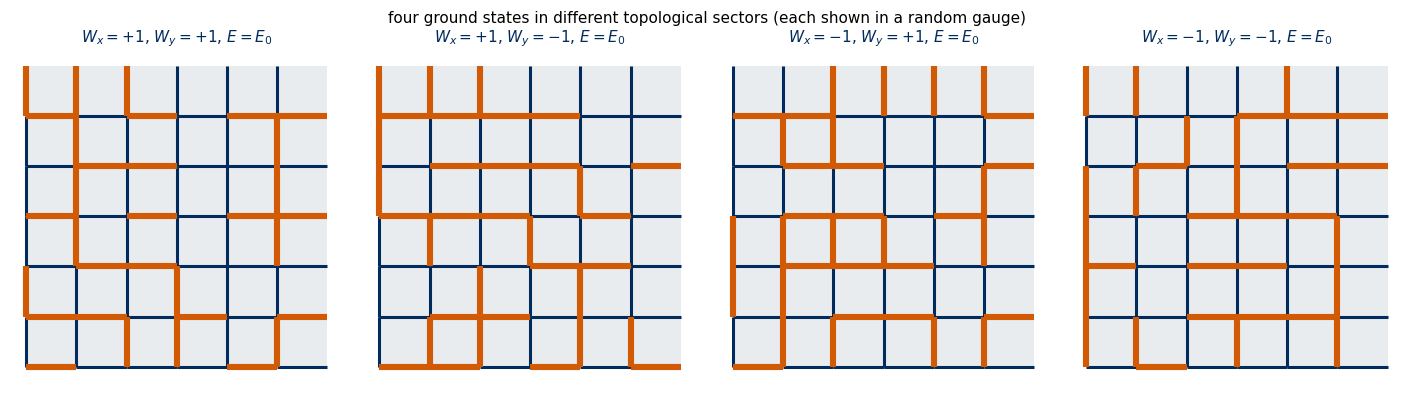

In [19]:
# one representative of each 2D topological sector on a 6x6 torus: flip a full non-contractible column / row of links
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
for k, (fx, fy) in enumerate(itertools.product((False, True), repeat=2)):
    Ur = np.ones((2, 6, 6), np.float32)
    if fx: Ur[0, 2, :] = -1          # horizontal links crossing the vertical line x = 2.5: flips W_x, keeps all plaquettes
    if fy: Ur[1, :, 3] = -1          # vertical links crossing the horizontal line y = 3.5: flips W_y
    Ur = np.asarray(gauge_transform(Ur, rng.choice([-1, 1], size=(6, 6)).astype(np.float32)))   # hide it by a random gauge
    draw_2d(ax[k], Ur, f"$W_x={Wx(Ur, 0):+.0f}$, $W_y={Wy(Ur, 0):+.0f}$, $E=E_0$")
plt.suptitle("four ground states in different topological sectors (each shown in a random gauge)", fontsize=10)
plt.tight_layout(); plt.show()

All four panels have every plaquette satisfied (no orange squares), the links look random because of the random gauge, and the only difference between them is the product of
links along a loop that winds around the torus.

At nonzero temperature, however, the sectors are not protected in 2D. Frustrated plaquettes cost only $2J$ each and are independent. Flipping one horizontal link of the row $y$ creates (or removes)
the two frustrated plaquettes above and below it and changes the sign of $W_x$ measured on that row; a pair created in this way can separate and wander around the torus,
so the value of $W_x$ is not conserved. To see this we follow $W_x$ on row $y=0$ along Monte Carlo chains on an $8\times8$ torus (raw chains, no gauge randomisation; $W_x$ is
gauge invariant anyway) and count how often it changes sign.

In [20]:
@partial(jax.jit, static_argnames=("n_sweeps",))
def trace_holonomy(U0, key, beta, masks, n_sweeps):
    # 2D: W_x measured on row y = 0 after every sweep, shape (n_sweeps,)
    def step(c, _):
        U, key = sweep(c[0], c[1], beta, masks)
        return (U, key), jnp.prod(U[0, :, 0])
    return lax.scan(step, (U0, key), None, length=n_sweeps)[1]

L, n_sw = 8, 20000
t0 = time.perf_counter()
for bv in (0.5, 1.0, 1.5, 2.0, 2.5):
    keys = jax.random.split(jax.random.PRNGKey(int(bv * 10)), 4)
    tr = np.asarray(jax.vmap(lambda k: trace_holonomy(jnp.ones((2, L, L)), k, bv, parity_masks(2, L), n_sw))(keys))
    flips = (np.diff(tr, axis=1) != 0).sum(1)
    print(f"beta = {bv}: sign changes of W_x in {n_sw} sweeps (4 chains): {flips.tolist()}   <W_x> = {tr.mean():+.3f}")
print(f"({time.perf_counter() - t0:.1f} s)")

beta = 0.5: sign changes of W_x in 20000 sweeps (4 chains): [9963, 10017, 9948, 9960]   <W_x> = -0.003


beta = 1.0: sign changes of W_x in 20000 sweeps (4 chains): [9164, 9193, 9282, 9176]   <W_x> = +0.005


beta = 1.5: sign changes of W_x in 20000 sweeps (4 chains): [5656, 5611, 5584, 5621]   <W_x> = +0.008


beta = 2.0: sign changes of W_x in 20000 sweeps (4 chains): [2093, 2163, 2123, 1990]   <W_x> = -0.003


beta = 2.5: sign changes of W_x in 20000 sweeps (4 chains): [354, 404, 380, 457]   <W_x> = +0.051
(9.7 s)


The sign changes become rarer as $\beta$ grows (each needs a pair of frustrated plaquettes, of energy $4J$ above the ground state), but they never stop, and $\langle W_x\rangle$ stays
close to zero: in 2D at $T>0$ the sectors are mixed. The four-fold degeneracy is a property of the ground states.

To summarise the two-dimensional model: the plaquettes are independent, $\langle U_p\rangle=\tanh\beta$ and $c=\beta^2/\cosh^2\beta$ with no transition, Wilson loops obey the area law at all $T$ (confinement),
and the ground states form $4$ topological sectors on the torus. In 3D the plaquettes are **no longer independent**, and this is what makes a phase transition possible.

<hr/>
## 5. The deconfinement transition in three dimensions

### 5.1 Flux loops
A three-dimensional lattice has elementary cubes, and they constrain the plaquettes. Each link of a cube lies on exactly two of its six faces. Therefore the product of the six face plaquettes is $\prod\sigma_l^2=1$:
**every cube has an even number of frustrated faces**. In 3D the dual of a plaquette is a link of the dual lattice (the lattice of cube centres) piercing it, so the frustrated plaquettes
form **closed loops on the dual lattice**, called flux loops. The smallest one is created by flipping a single link: it frustrates the $4$ plaquettes around that link, a dual loop of length $4$.

The competition between the energy and the entropy of flux loops drives a transition. A flux loop of length $\ell$ costs $2J\ell$, and the number of such loops grows exponentially with $\ell$, as for the domain walls of the 2D Ising model
(Lab 012, Section 3.3). At small $T$ (large $\beta$) only small loops occur; at high $T$ arbitrarily long loops proliferate, and between the two regimes there is a transition.
In 2D there is no such constraint (a 2D lattice has no cubes), plaquettes are independent point defects, and nothing happens.

The sketch below shows the smallest flux loop in three dimensions: one flipped link (orange) frustrates the four plaquettes around it, and the dual links that pierce these plaquettes (purple) form a closed square on the dual lattice.

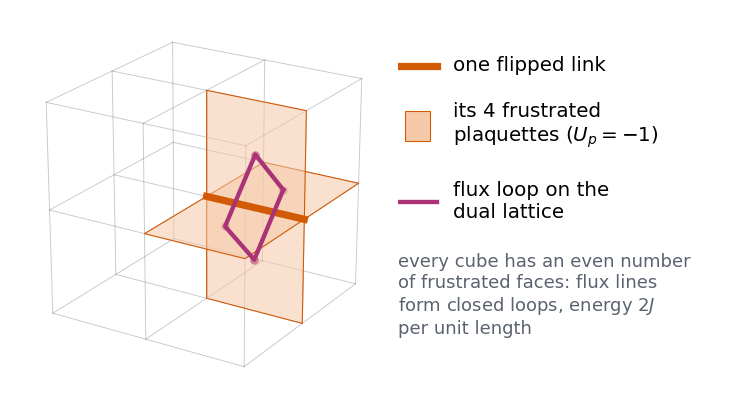

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def sketch_flux_loop():
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.0, 0.55, 1.0], projection="3d"); tx = fig.add_axes([0.55, 0.0, 0.45, 1.0]); tx.axis("off")
    rng3 = range(3)
    for a in rng3:                                                  # faint cubic lattice with 3 x 3 x 3 sites
        for b in rng3:
            ax.plot([0, 2], [a, a], [b, b], color=GRAY, lw=0.5, alpha=0.35)
            ax.plot([a, a], [0, 2], [b, b], color=GRAY, lw=0.5, alpha=0.35)
            ax.plot([a, a], [b, b], [0, 2], color=GRAY, lw=0.5, alpha=0.35)
    # the flipped link from (1, 1, 1) to (2, 1, 1) and the 4 plaquettes that contain it
    ax.plot([1, 2], [1, 1], [1, 1], color=ORANGE, lw=4, zorder=10)
    plaquettes = [[(1, 1, 1), (2, 1, 1), (2, 2, 1), (1, 2, 1)], [(1, 0, 1), (2, 0, 1), (2, 1, 1), (1, 1, 1)],
                  [(1, 1, 1), (2, 1, 1), (2, 1, 2), (1, 1, 2)], [(1, 1, 0), (2, 1, 0), (2, 1, 1), (1, 1, 1)]]
    ax.add_collection3d(Poly3DCollection(plaquettes, facecolor="#F6C9A8", edgecolor=ORANGE, lw=0.6, alpha=0.55))
    # the flux loop: dual links through the centres of the 4 frustrated plaquettes, encircling the flipped link
    loop = np.array([(1.5, 1.5, 1), (1.5, 1, 1.5), (1.5, 0.5, 1), (1.5, 1, 0.5)])
    loop = np.vstack([loop, loop[:1]])
    ax.plot(loop[:, 0], loop[:, 1], loop[:, 2], color=PURPLE, lw=2.4, zorder=11)
    ax.scatter(loop[:-1, 0], loop[:-1, 1], loop[:-1, 2], color=PURPLE, s=14, depthshade=False)
    ax.view_init(elev=22, azim=-58)
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
    ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_zlim(0, 2)

    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.plot([0.0, 0.12], [0.86, 0.86], color=ORANGE, lw=4)
    tx.text(0.17, 0.86, "one flipped link", fontsize=11, va="center")
    tx.add_patch(mpatches.Rectangle((0.02, 0.66), 0.08, 0.08, fc="#F6C9A8", ec=ORANGE, lw=0.6))
    tx.text(0.17, 0.7, "its 4 frustrated\nplaquettes ($U_p=-1$)", fontsize=11, va="center")
    tx.plot([0.0, 0.12], [0.5, 0.5], color=PURPLE, lw=2.4)
    tx.text(0.17, 0.5, "flux loop on the\ndual lattice", fontsize=11, va="center")
    tx.text(0.0, 0.25, "every cube has an even number\nof frustrated faces: flux lines\nform closed loops, energy $2J$\nper unit length", fontsize=10, color=GRAY, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_flux_loop()
save_sketch(fig, "sketch_gauge_flux_loop.png")
plt.show()


The cell below checks the cube constraint on a random
configuration and counts the plaquettes frustrated by a single flipped link.

In [21]:
def cube_products(U):
    # 3D: product of the six faces of every elementary cube, shape (L, L, L); faces: plane (0,1) at x and x+e_2, (0,2) at x and x+e_1, (1,2) at x and x+e_0
    P = plaquettes(U)
    return P[0] * shift(P[0], 2) * P[1] * shift(P[1], 1) * P[2] * shift(P[2], 0)

Ur3 = rng.choice([-1, 1], size=(3, 6, 6, 6)).astype(np.float32)
print("random 3D configuration: all cube products = +1:", bool(np.all(np.asarray(cube_products(Ur3)) == 1)))
U1 = np.ones((3, 6, 6, 6), np.float32); U1[2, 1, 2, 3] = -1
print("one flipped link frustrates", int((np.asarray(plaquettes(U1)) < 0).sum()), "plaquettes (a flux loop of length 4)")

random 3D configuration: all cube products = +1: True
one flipped link frustrates 4 plaquettes (a flux loop of length 4)


On a random configuration every cube product equals $+1$, and a single flipped link frustrates exactly $4$ plaquettes, the shortest flux loop.

### 5.2 Wegner duality
The derivation parallels Kramers–Wannier duality (Lab 012, Sections 4–5): two expansions count the same geometric objects.

On the Ising side we use the high-temperature expansion. For $H_I=-\sum_{\langle ij\rangle}s_is_j$ on the cubic lattice at coupling $K$, with $e^{Kss'}=\cosh K(1+ss'\tanh K)$ (Lab 012, Section 4.1),
$$
Z_I(K) = 2^N(\cosh K)^{3N}\sum_{G\ \text{closed}}(\tanh K)^{|G|},
$$
the sum running over **closed graphs** $G$ on the cubic lattice (every site touched by an even number of bonds of $G$), with $|G|$ the number of bonds.

On the gauge side we use the low-temperature expansion. Start from all $U_p=+1$, energy $-3N$. A configuration whose frustrated plaquettes form the set $F$ has weight $e^{3N\beta}e^{-2\beta|F|}$.
By Section 5.1, $F$ is a set of closed loops on the dual lattice, which is again a simple cubic lattice. Every allowed $F$ is realised by the same number of link configurations
(one gauge orbit of size $2^{N-1}$ times the $2^3$ holonomy sectors), so
$$
Z_g(\beta) = 2^{N-1}\,2^3\,e^{3N\beta}\sum_{F\ \text{closed on the dual lattice}}\big(e^{-2\beta}\big)^{|F|},
$$
up to loops that wind around the torus, whose weight per site vanishes for $N\to\infty$.

Both sums are the same function $g(y)=\lim_{N\to\infty}\frac1N\ln\sum_{G\ \rm closed}y^{|G|}$ of the cubic lattice. Hence, per site,
$$
\begin{aligned}
\varphi_g(\beta) &\equiv \lim\frac{\ln Z_g}{N} = \ln2 + 3\beta + g\big(e^{-2\beta}\big),\\
\varphi_I(K) &= \ln2 + 3\ln\cosh K + g(\tanh K),
\end{aligned}
$$
$$
\boxed{\ \tanh K = e^{-2\beta}\ }\quad\Longrightarrow\quad \varphi_g(\beta) - 3\beta = \varphi_I(K) - 3\ln\cosh K .
$$
[F. J. Wegner, J. Math. Phys. **12**, 2259 (1971); J. B. Kogut, Rev. Mod. Phys. **51**, 659 (1979)]
The map is **decreasing**: weak gauge coupling (large $\beta$, low $T$) corresponds to small $K$, the **disordered** Ising phase, and vice versa.
The 3D model is not self-dual (unlike the 2D Ising model): it is dual to a *different* model, and the free energies are equal up to analytic terms. So the gauge theory has a
singularity exactly where the Ising model has one, of the same type.

The duality therefore maps the critical point of one model onto the critical point of the other. With the 3D Ising critical coupling from high-precision Monte Carlo, $K_c^{I}=0.221654626(5)$ [Ferrenberg, Xu, Landau, Phys. Rev. E **97**, 043301 (2018)],
the critical coupling of the gauge theory is
$$
\beta_c = -\tfrac12\ln\tanh K_c^{I},
$$
which the cell below evaluates to $\beta_c=0.761413$. Differentiating the boxed identity with respect to $\beta$ ($3N$ plaquettes and $3N$ bonds per $N$ sites) also gives a relation between quantities
that can be measured in the two models:
$$
\begin{aligned}
\langle U_p\rangle_g(\beta) &= 1 + \frac{dK}{d\beta}\Big(\langle s_is_j\rangle_I(K)-\tanh K\Big),\\
\frac{dK}{d\beta} &= -\frac{1}{\sinh2\beta},
\end{aligned}
$$
where $\langle s_is_j\rangle_I$ is the nearest-neighbour correlation of the Ising model. We derive it in SymPy and test it with two independent Monte Carlo simulations.

In [22]:
# SymPy: the duality map, its derivative, the energy relation and the critical coupling
K = sp.symbols("K", positive=True)
K_of_beta = sp.atanh(sp.exp(-2 * b))
dKdb = sp.simplify(sp.diff(K_of_beta, b))
print("K(beta) = atanh(exp(-2 beta)),   dK/dbeta =", dKdb, "   equals -1/sinh(2 beta):",
      sp.simplify((dKdb + 1 / sp.sinh(2 * b)).rewrite(sp.exp)) == 0)

phi_I = sp.Function("phi_I")                                   # Ising free energy per site, unknown function
phi_g = 3 * b + phi_I(K_of_beta) - 3 * sp.log(sp.cosh(K_of_beta))
U_from_duality = sp.diff(phi_g, b) / 3                          # <U_p> = (1/3) d phi_g / d beta
e_I = sp.Symbol("e_I")                                          # <s_i s_j>_I = (1/3) d phi_I / dK  (3 bonds per site)
print("(1/3) d phi_g/d beta =", U_from_duality)
expr = U_from_duality.replace(lambda e: isinstance(e, (sp.Subs, sp.Derivative)), lambda e: 3 * e_I)
target = 1 - (e_I - sp.tanh(K_of_beta)) / sp.sinh(2 * b)
print("<U_p> - [1 - (e_I - tanh K)/sinh 2beta] =", sp.simplify((expr - target).rewrite(sp.exp)))

# critical coupling, with 30 significant digits, and the propagated uncertainty of K_c
Kc_I = sp.Float("0.221654626", 30); dKc = 5e-9
beta_c_expr = -sp.log(sp.tanh(K)) / 2
beta_c = beta_c_expr.subs(K, Kc_I).evalf(20)
dbeta_dK = sp.diff(beta_c_expr, K)
print(f"K_c(3D Ising) = {Kc_I:.9f}   tanh K_c = {float(sp.tanh(Kc_I)):.10f}")
print(f"beta_c(gauge) = -1/2 ln tanh K_c = {float(beta_c):.9f} +- {abs(float(dbeta_dK.subs(K, Kc_I))) * dKc:.0e}")
print("check: dbeta/dK = -1/sinh(2K)?", sp.simplify((dbeta_dK + 1 / sp.sinh(2 * K)).rewrite(sp.exp)) == 0,
      f";  T_c = 1/beta_c = {1 / float(beta_c):.7f} J/k_B")
BETA_C = float(beta_c); KC_I = float(Kc_I)

K(beta) = atanh(exp(-2 beta)),   dK/dbeta = -1/sinh(2*beta)    equals -1/sinh(2 beta): True
(1/3) d phi_g/d beta = 1 - 2*exp(-2*beta)*Subs(Derivative(phi_I(_xi_1), _xi_1), _xi_1, atanh(exp(-2*beta)))/(3*(1 - exp(-4*beta))) + 2*exp(-4*beta)/(1 - exp(-4*beta))
<U_p> - [1 - (e_I - tanh K)/sinh 2beta] = 0


K_c(3D Ising) = 0.221654626   tanh K_c = 0.2180945523
beta_c(gauge) = -1/2 ln tanh K_c = 0.761413292 +- 1e-08


check: dbeta/dK = -1/sinh(2K)? True ;  T_c = 1/beta_c = 1.3133472 J/k_B


The map $\beta\leftrightarrow K$ is its own inverse in form: $\tanh K=e^{-2\beta}$ is equivalent to $\tanh\beta=e^{-2K}$ (the same algebra as Lab 012, Section 5, Step 3), which is why
$d\beta/dK=-1/\sinh2K$ has the same shape as $dK/d\beta$.

### 5.3 The duality energy relation
The energy relation connects two different models, so it can be tested with two independent simulations. We simulate the 3D Ising model at the dual couplings $K(\beta)$, measure $\langle s_is_j\rangle_I$, predict $\langle U_p\rangle_g$ from the energy relation, and compare with direct
gauge-theory Monte Carlo, both on $L=8$ lattices. We stay away from $\beta_c$, where finite-size effects differ between the two models.

In [23]:
@partial(jax.jit, static_argnames=("n_equil", "n_samples", "n_between"))
def ising_chains(s0, keys, Ks, chess, n_equil, n_samples, n_between):
    # per chain: nearest-neighbour correlation (1/3N) sum_<ij> s_i s_j of n_samples stored configurations, shape (chains, n_samples)
    def one(s, key, K):
        step = lambda c, _: (ising_sweep(c[0], c[1], K, chess), None)
        carry, _ = lax.scan(step, (s, key), None, length=n_equil)
        def store(c, _):
            c, _ = lax.scan(step, c, None, length=n_between)
            s = c[0]
            return c, sum(jnp.mean(s * jnp.roll(s, 1, a)) for a in range(3)) / 3
        return lax.scan(store, carry, None, length=n_samples)[1]
    return jax.vmap(one)(s0, keys, Ks)

beta_dual = np.array([0.40, 0.50, 0.60, 0.95, 1.10, 1.30])
K_dual = np.arctanh(np.exp(-2 * beta_dual))
L, n_rep = 8, 16
t0 = time.perf_counter()
Ks = jnp.repeat(jnp.asarray(K_dual, jnp.float32), n_rep)
eI = np.asarray(ising_chains(jnp.ones((Ks.size, L, L, L)), jax.random.split(jax.random.PRNGKey(5), Ks.size), Ks,
                             chessboard(L), 1000, 400, 2)).reshape(len(K_dual), n_rep, -1).mean(2)     # (n_beta, n_rep)
gl = run_gauge(3, L, beta_dual, n_rep, n_equil=1000, n_samples=400, n_between=2, seed=6)
Ug = np.asarray(mean_plaq(jnp.asarray(gl.reshape(-1, 3, L, L, L), jnp.float32))).reshape(len(beta_dual), n_rep, -1).mean(2)
print(f"({time.perf_counter() - t0:.1f} s)")
print(" beta_g    K_I = atanh(e^-2beta)   <s_i s_j>_I        <U_p> predicted     <U_p> gauge MC     difference / error")
for i, bv in enumerate(beta_dual):
    pred = 1 - (eI[i] - np.tanh(K_dual[i])) / np.sinh(2 * bv)
    e_pred, e_mc = pred.std(ddof=1) / np.sqrt(n_rep), Ug[i].std(ddof=1) / np.sqrt(n_rep)
    print(f"  {bv:.2f}        {K_dual[i]:.4f}         {eI[i].mean():.5f}+-{eI[i].std(ddof=1)/np.sqrt(n_rep):.5f}   "
          f"{pred.mean():.5f}+-{e_pred:.5f}   {Ug[i].mean():.5f}+-{e_mc:.5f}   {(pred.mean() - Ug[i].mean()) / np.hypot(e_pred, e_mc):+.1f}")

(35.2 s)
 beta_g    K_I = atanh(e^-2beta)   <s_i s_j>_I        <U_p> predicted     <U_p> gauge MC     difference / error
  0.40        0.4839         0.98691+-0.00009   0.39469+-0.00011   0.39523+-0.00031   -1.7
  0.50        0.3860         0.95246+-0.00030   0.50257+-0.00026   0.50156+-0.00042   +2.0
  0.60        0.3108         0.86445+-0.00058   0.62685+-0.00038   0.62747+-0.00045   -1.1
  0.95        0.1507         0.16680+-0.00038   0.99473+-0.00012   0.99459+-0.00007   +1.0
  1.10        0.1113         0.11615+-0.00031   0.99880+-0.00007   0.99859+-0.00004   +2.5
  1.30        0.0744         0.07590+-0.00041   0.99976+-0.00006   0.99973+-0.00002   +0.4


The prediction from the Ising simulation and the direct gauge simulation agree to about $10^{-3}$ on both sides of $\beta_c$, with differences of at most a few combined standard errors (last column; the errors come from only 16 chains per coupling): two different models, one free energy.
Note the direction of the map in the table: $\beta_g<\beta_c$ corresponds to $K_I>K_c^I$ (ordered Ising magnet), and $\beta_g>\beta_c$ to the disordered Ising magnet.

### 5.4 The 3D data sets
The 3D simulations use lattices $L=6,8,10$ and couplings from $0.3$ to $1.2$ in steps of $0.05$, refined to steps of $0.01$ in $[0.70,0.82]$ around $\beta_c$.
Chains start cold ($\sigma\equiv+1$), a configuration without flux loops; the cell below checks, deep in the deconfined phase, that a random (hot) start gives the same
plaquette average after equilibration.
The statistics are modest: independent chains with local updates near a continuous transition suffer from critical slowing down (Lab 018, Section 2.2), so the error bars near
$\beta_c$ are the largest.

The 3D data set has the same keys as in 2D, and `links` of shape `(n_beta, n_samples, 3, L, L, L)`:
`links[i, k, mu, x, y, z]` $=\sigma_\mu(x,y,z)$, $\mu=0,1,2$ the directions $x,y,z$.

In [24]:
# cold against hot start, deep in the deconfined phase: mean plaquette after equilibration, L = 6
L, bv, n_ch = 6, 1.0, 16
t0 = time.perf_counter()
keys = jax.random.split(jax.random.PRNGKey(77), 2 * n_ch)
U_cold = jnp.ones((n_ch, 3, L, L, L))
U_hot = jnp.where(jax.random.bernoulli(jax.random.PRNGKey(78), 0.5, (n_ch, 3, L, L, L)), 1.0, -1.0)
res = {}
for name, U0 in (("cold", U_cold), ("hot", U_hot)):
    smp_cs = gauge_chains(U0, keys[:n_ch] if name == "cold" else keys[n_ch:], jnp.full(n_ch, bv), parity_masks(3, L), 2000, 100, 5)
    res[name] = np.asarray(mean_plaq(jnp.asarray(smp_cs.reshape(-1, 3, L, L, L), jnp.float32))).reshape(n_ch, -1).mean(1)   # (n_ch,)
    print(f"{name} start, beta = {bv}: <U_p> per chain = {np.round(res[name], 4)}")
print(f"({time.perf_counter() - t0:.1f} s)")

cold start, beta = 1.0: <U_p> per chain = [0.9974 0.9973 0.997  0.9971 0.9947 0.9967 0.9972 0.9971 0.9962 0.9959
 0.9969 0.9951 0.997  0.9952 0.9973 0.997 ]


hot start, beta = 1.0: <U_p> per chain = [0.9967 0.9962 0.9975 0.9983 0.997  0.9966 0.9972 0.9966 0.996  0.9978
 0.9967 0.9969 0.9967 0.9969 0.9964 0.997 ]
(24.5 s)


In [25]:
BETAS_3D = np.unique(np.round(np.concatenate([np.arange(0.30, 1.201, 0.05), np.arange(0.70, 0.821, 0.01)]), 3))
print(f"{len(BETAS_3D)} couplings:", BETAS_3D)
print(f"beta_c from duality = {BETA_C:.6f}")
t0 = time.perf_counter()
ds3 = {L: make_dataset(3, L, BETAS_3D, n_rep=16, n_equil=600, n_samples=64, n_between=4,
                       seed=3000 + L) for L in (6, 8, 10)}
print(f"3D data sets ready: {time.perf_counter() - t0:.1f} s")

29 couplings: [0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.71 0.72 0.73 0.74 0.75
 0.76 0.77 0.78 0.79 0.8  0.81 0.82 0.85 0.9  0.95 1.   1.05 1.1  1.15
 1.2 ]
beta_c from duality = 0.761413


generated and saved 3D, L = 6: links (29, 1024, 3, 6, 6, 6), 33.1 s, 2.9 MB


generated and saved 3D, L = 8: links (29, 1024, 3, 8, 8, 8), 47.1 s, 6.9 MB


generated and saved 3D, L = 10: links (29, 1024, 3, 10, 10, 10), 124.1 s, 13.5 MB
3D data sets ready: 204.4 s


With the data in hand we measure, as in 2D, $\langle U_p\rangle=\langle\bar U\rangle$ and $c=\beta^2N_p\big(\langle\bar U^2\rangle-\langle\bar U\rangle^2\big)$, now with $N_p=3L^3$.
The dotted line marks $\beta_c$ from duality. For comparison we draw the 2D result $\tanh\beta$, which is also the leading strong-coupling (small-$\beta$) behaviour $\langle U_p\rangle\approx\tanh\beta$
in any dimension, because the first closed surface in 3D, a cube, needs $6$ plaquettes (Exercise 4).

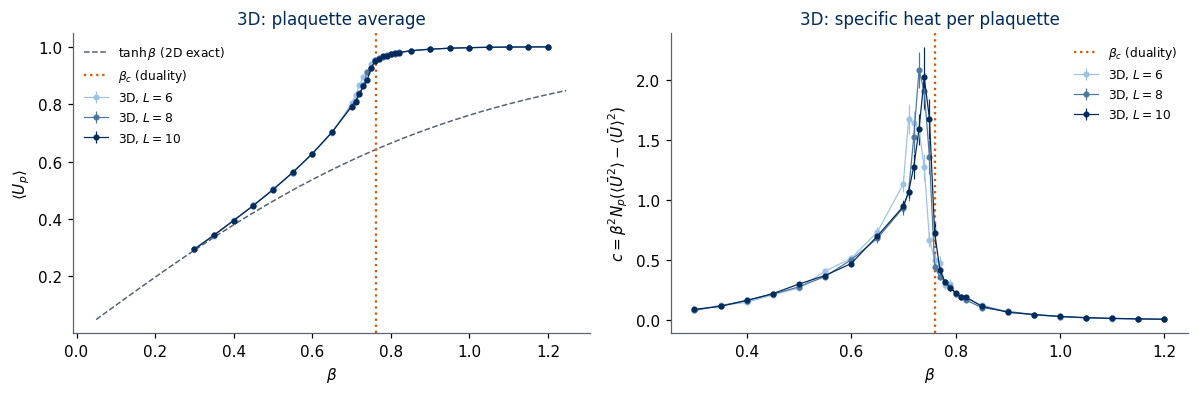

specific-heat peak (parabola through the three highest points of the fine grid):
  L =  6: c_max = 1.677, beta_peak = 0.7145   (beta_c from duality = 0.7614)
  L =  8: c_max = 2.087, beta_peak = 0.7326   (beta_c from duality = 0.7614)
  L = 10: c_max = 2.025, beta_peak = 0.7406   (beta_c from duality = 0.7614)


In [26]:
st3 = {L: plaquette_stats(ds3[L]) for L in ds3}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
ax[0].plot(bf[bf < 1.25], np.tanh(bf[bf < 1.25]), color=UJGray, lw=1, ls="--", label=r"$\tanh\beta$ (2D exact)")
for i, L in enumerate(st3):
    ax[0].errorbar(BETAS_3D, st3[L]["U"], st3[L]["dU"], fmt="o-", ms=3, lw=0.8, color=blues(i / 2), label=f"3D, $L={L}$")
    ax[1].errorbar(BETAS_3D, st3[L]["c"], st3[L]["dc"], fmt="o-", ms=3, lw=0.8, color=blues(i / 2), label=f"3D, $L={L}$")
for a in ax:
    a.axvline(BETA_C, color=DSOrange, ls=":", lw=1.5, label=r"$\beta_c$ (duality)"); a.set_xlabel(r"$\beta$"); a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel(r"$\langle U_p\rangle$"); ax[1].set_ylabel(r"$c=\beta^2N_p(\langle\bar U^2\rangle-\langle\bar U\rangle^2)$")
ax[0].set_title("3D: plaquette average"); ax[1].set_title("3D: specific heat per plaquette")
plt.tight_layout(); plt.show()

print("specific-heat peak (parabola through the three highest points of the fine grid):")
fine = (BETAS_3D >= 0.70) & (BETAS_3D <= 0.82)
for L in st3:
    bb, cc = BETAS_3D[fine], st3[L]["c"][fine]
    k = int(np.clip(np.argmax(cc), 1, len(cc) - 2))
    a2, a1, a0 = np.polyfit(bb[k - 1:k + 2], cc[k - 1:k + 2], 2)
    print(f"  L = {L:2d}: c_max = {cc.max():.3f}, beta_peak = {-a1 / (2 * a2):.4f}   (beta_c from duality = {BETA_C:.4f})")

In contrast to 2D, $\langle U_p\rangle$ rises steeply around $\beta_c$, and the specific heat has a sharp peak, several times higher than the maximum of the smooth 2D curve $\beta^2/\cosh^2\beta$ (Section 4.3).
The peak positions of finite lattices are shifted from $\beta_c$ by finite-size effects ($0.7145$, $0.7326$ and $0.7406$ for $L=6,8,10$, against $\beta_c=0.7614$), and the shift shrinks as $L$ grows (Lab 019 discusses the scaling of such shifts). With this statistics and this $\beta$ grid the peak heights of $L=8$ and $L=10$ are not resolved from each other; the growth of the peak with $L$ requires longer runs and a finer grid (or histogram reweighting).
The duality fixes the type of singularity: the free energy of the gauge theory equals that of the 3D Ising model plus analytic terms, so its specific heat has the same singular behaviour as the specific heat of the 3D Ising model.

### 5.5 Area law and perimeter law
The plaquette average shows that something happens at $\beta_c$; the Wilson loops show what. In the confined phase ($\beta<\beta_c$, high $T$) flux loops proliferate, and every loop of the lattice is pierced by many of them at random. The Wilson loop then decays with the area,
$W(R,T)\sim e^{-\sigma_sRT}$, as in 2D; to leading order at small $\beta$, $W\approx(\tanh\beta)^{RT}$ (tile the minimal surface with plaquettes).
In the deconfined phase ($\beta>\beta_c$, low $T$) flux loops are small and rare. Only the small loops that pierce the surface close to its boundary contribute
(a small loop deep inside pierces the surface twice and contributes $(-1)^2$), so $W(R,T)\sim e^{-\mu\,2(R+T)}$: a **perimeter law** with a constant $\mu$.

Area and perimeter terms can be separated without fitting by the ratio proposed by Creutz [Phys. Rev. D **21**, 2308 (1980)],
$$
\chi(R,T) = -\ln\frac{W(R,T)\,W(R-1,T-1)}{W(R,T-1)\,W(R-1,T)} .
$$
For $W=e^{-\sigma_sRT-2\mu(R+T)-c_0}$ the perimeter terms and the constant $c_0$ cancel and $\chi=\sigma_s$ exactly; with a pure perimeter law $\chi=0$.
With $W(0,T)=W(R,0)=1$, $\chi(1,1)=-\ln W(1,1)=-\ln\langle U_p\rangle$.

Wilson loops up to 4x4 on L = 10: 8.4 s


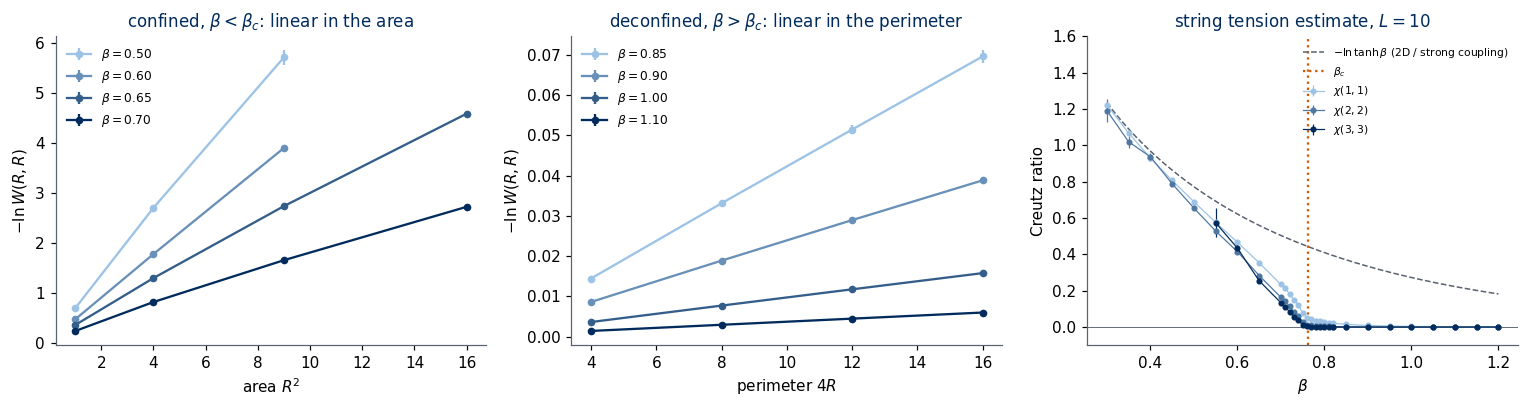

 beta    chi(1,1)          chi(2,2)          chi(3,3)
 0.40  +0.930+-0.001  +0.937+-0.022  +0.021+-1.246
 0.55  +0.576+-0.001  +0.528+-0.008  +0.574+-0.081
 0.65  +0.354+-0.001  +0.283+-0.003  +0.254+-0.008
 0.72  +0.182+-0.002  +0.114+-0.003  +0.084+-0.004
 0.76  +0.052+-0.002  +0.012+-0.001  +0.004+-0.001
 0.80  +0.027+-0.001  +0.003+-0.000  +0.001+-0.000
 0.90  +0.009+-0.000  +0.000+-0.000  +0.000+-0.000
 1.00  +0.004+-0.000  +0.000+-0.000  +0.000+-0.000
 1.10  +0.001+-0.000  +0.000+-0.000  +0.000+-0.000


In [27]:
L, Rmax = 10, 4
t0 = time.perf_counter()
W3 = np.zeros((len(BETAS_3D), Rmax, Rmax)); dW3 = np.zeros((len(BETAS_3D), Rmax)); dchi = np.zeros((len(BETAS_3D), Rmax)); chi = np.zeros((len(BETAS_3D), Rmax))
for i in range(len(BETAS_3D)):
    Wt = wilson_table(ds3[L]["links"][i], Rmax)                         # (n_samples, Rmax, Rmax)
    Wp = np.pad(Wt, ((0, 0), (1, 0), (1, 0)), constant_values=1.0)      # W(0, T) = W(R, 0) = 1
    W3[i] = Wt.mean(0)
    dW3[i] = [per_chain(Wt[:, R, R], ds3[L]["chain"]).std(ddof=1) / np.sqrt(int(ds3[L]["n_rep"])) for R in range(Rmax)]
    # Creutz ratios chi(R,R) and their spread over chains (jackknife over chains)
    ch = ds3[L]["chain"]; reps = np.unique(ch)
    def creutz(Wm):
        return np.array([-np.log(Wm[R, R] * Wm[R - 1, R - 1] / (Wm[R, R - 1] * Wm[R - 1, R])) for R in range(1, Rmax + 1)])
    with np.errstate(invalid="ignore", divide="ignore"):         # log of a negative noisy ratio -> nan, not plotted
        chi[i] = creutz(Wp.mean(0))
        jk = np.array([creutz(Wp[ch != r].mean(0)) for r in reps])
        dchi[i] = np.sqrt((len(reps) - 1) * np.var(jk, axis=0))
print(f"Wilson loops up to {Rmax}x{Rmax} on L = {L}: {time.perf_counter() - t0:.1f} s")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
Rs = np.arange(1, Rmax + 1)
for k, (panel, blist) in enumerate(((0, (0.50, 0.60, 0.65, 0.70)), (1, (0.85, 0.90, 1.00, 1.10)))):
    for j, bv in enumerate(blist):
        i = int(np.argmin(np.abs(BETAS_3D - bv)))
        Wd = np.array([W3[i, R - 1, R - 1] for R in Rs]); eW = np.array([dW3[i, R - 1] for R in Rs])
        keep = Wd > 3 * eW                                         # only loops measured with significance
        x = Rs**2 if panel == 0 else 4 * Rs
        ax[panel].errorbar(x[keep], -np.log(Wd[keep]), eW[keep] / Wd[keep], fmt="o-", ms=4, color=blues(j / 3),
                           label=fr"$\beta={BETAS_3D[i]:.2f}$")
ax[0].set_xlabel("area $R^2$"); ax[1].set_xlabel("perimeter $4R$")
for a in ax[:2]: a.set_ylabel(r"$-\ln W(R,R)$"); a.legend(frameon=False, fontsize=8)
ax[0].set_title(r"confined, $\beta<\beta_c$: linear in the area"); ax[1].set_title(r"deconfined, $\beta>\beta_c$: linear in the perimeter")
for R in (1, 2, 3):
    ok = np.isfinite(chi[:, R - 1]) & np.isfinite(dchi[:, R - 1]) & (dchi[:, R - 1] < 0.1)
    ax[2].errorbar(BETAS_3D[ok], chi[ok, R - 1], dchi[ok, R - 1], fmt="o-", ms=3, lw=0.8, color=blues((R - 1) / 2), label=fr"$\chi({R},{R})$")
bb = np.linspace(0.3, 1.2, 200)
ax[2].plot(bb, -np.log(np.tanh(bb)), color=UJGray, ls="--", lw=1, label=r"$-\ln\tanh\beta$ (2D / strong coupling)")
ax[2].axvline(BETA_C, color=DSOrange, ls=":", lw=1.5, label=r"$\beta_c$"); ax[2].axhline(0, color=UJGray, lw=0.6)
ax[2].set_xlabel(r"$\beta$"); ax[2].set_ylabel("Creutz ratio"); ax[2].set_ylim(-0.1, 1.6); ax[2].legend(frameon=False, fontsize=7)
ax[2].set_title(f"string tension estimate, $L={L}$")
plt.tight_layout(); plt.show()

print(" beta    chi(1,1)          chi(2,2)          chi(3,3)")
for bv in (0.40, 0.55, 0.65, 0.72, 0.76, 0.80, 0.90, 1.00, 1.10):
    i = int(np.argmin(np.abs(BETAS_3D - bv)))
    print(f" {BETAS_3D[i]:.2f}  " + "  ".join(f"{chi[i, R]:+.3f}+-{dchi[i, R]:.3f}" for R in range(3)))

Below $\beta_c$ the Creutz ratios $\chi(2,2)$ and $\chi(3,3)$ are clearly positive (at $\beta=0.65$, $\chi(2,2)=0.283$ and $\chi(3,3)=0.254$), a non-zero string tension: **confinement**. Above $\beta_c$ they drop to
values compatible with zero (zero to three decimals from $\beta=0.90$ on): perimeter law, **deconfinement**. The ratio $\chi(1,1)=-\ln\langle U_p\rangle$ contains the perimeter term and stays positive on both sides; only the larger
ratios measure the string tension. The ratios for larger loops are noisy, especially on the confined side where $W(R,R)$ is exponentially small, since Wilson loops of large area are
hard to measure; points with a jackknife error above $0.1$ are not plotted.

This is a phase transition without a local order parameter: the two phases are told apart by how a **non-local**, gauge-invariant observable scales with the size of the loop.

The schematic below contrasts the two phases of the 3D model on a two-dimensional slice of links. In the confined phase (small $\beta$, high temperature) the links are nearly random and about half of the plaquettes are frustrated. In the deconfined phase (large $\beta$, low temperature) almost every plaquette is satisfied; the links nevertheless look random, because a random gauge transformation (Section 3) has been applied, and it leaves every plaquette unchanged. The difference between the phases is invisible in single links and appears only in plaquettes and Wilson loops.

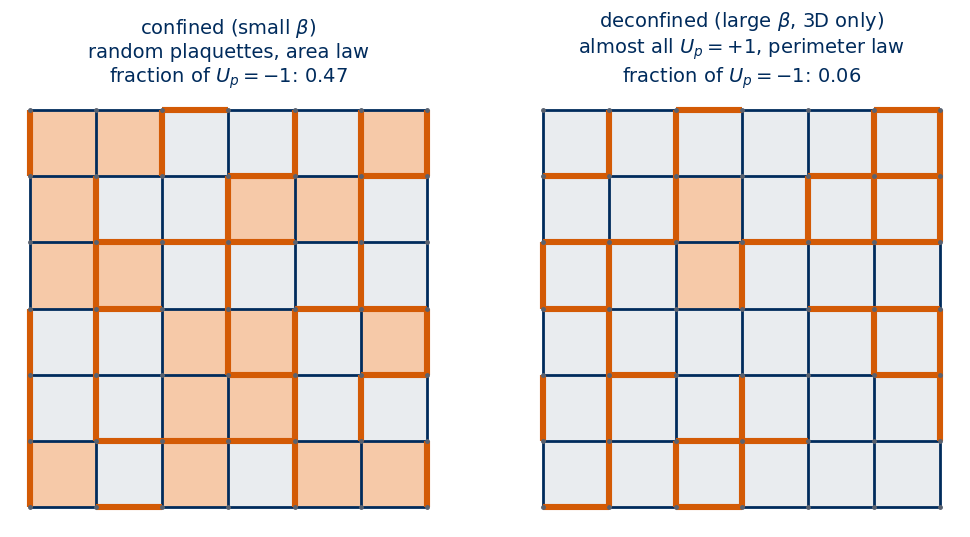

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

# links: sigma = +1 thin navy segment, sigma = -1 thick orange segment (as in the configuration plots of this notebook);
# plaquettes: light grey if U_p = +1, light orange if frustrated (U_p = -1)
def draw_links_2d(ax, U, lw=1.6, shade=True, sites=True):
    # U[mu, x, y]: U[0] horizontal link from (x, y) to (x+1, y), U[1] vertical link from (x, y) to (x, y+1); open patch
    n = U.shape[1]
    if shade:
        for x in range(n - 1):
            for y in range(n - 1):
                Up = U[0, x, y] * U[1, x + 1, y] * U[0, x, y + 1] * U[1, x, y]      # product of the four boundary links
                ax.add_patch(mpatches.Rectangle((x, y), 1, 1, color="#E9ECEF" if Up > 0 else "#F6C9A8", lw=0, zorder=0))
    for mu, (dx, dy) in enumerate([(1, 0), (0, 1)]):
        for x in range(n):
            for y in range(n):
                if x + dx < n and y + dy < n:
                    s = U[mu, x, y]
                    ax.plot([x, x + dx], [y, y + dy], color=NAVY if s > 0 else ORANGE, lw=lw if s > 0 else 2.2 * lw,
                            solid_capstyle="butt", zorder=2 if s > 0 else 3)
    if sites:
        for x in range(n):
            for y in range(n):
                ax.plot(x, y, "o", color=GRAY, ms=2.5, zorder=4)
    ax.set_xlim(-0.3, n - 0.7); ax.set_ylim(-0.3, n - 0.7); ax.set_aspect("equal"); ax.axis("off")

def sketch_gauge_phases_configs():
    n = 7
    rng = np.random.default_rng(4)                                  # fixed seed: the same schematic every time
    # confined phase (small beta): links nearly independent, about half of the plaquettes frustrated
    U_conf = rng.choice([-1, 1], size=(2, n, n))
    # deconfined phase (large beta, 3D): all U_p = +1 except around one flipped link, seen through a random gauge
    U_dec = np.ones((2, n, n), int); U_dec[0, 2, 4] = -1
    g = rng.choice([-1, 1], size=(n, n))                            # random gauge transformation g(x) on every site
    U_dec[0, :-1, :] *= g[:-1, :] * g[1:, :]                        # horizontal link (x, y) -> (x+1, y)
    U_dec[1, :, :-1] *= g[:, :-1] * g[:, 1:]                        # vertical link (x, y) -> (x, y+1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5.6))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.02, top=0.8, wspace=0.1)
    for ax, U, title in [(axes[0], U_conf, "confined (small $\\beta$)\nrandom plaquettes, area law"),
                         (axes[1], U_dec, "deconfined (large $\\beta$, 3D only)\nalmost all $U_p=+1$, perimeter law")]:
        draw_links_2d(ax, U, lw=2.0)
        P = U[0, :-1, :-1] * U[1, 1:, :-1] * U[0, :-1, 1:] * U[1, :-1, :-1]
        ax.set_title(f"{title}\nfraction of $U_p=-1$: {np.mean(P < 0):.2f}", fontsize=14, color=NAVY)
    return fig

with plt.rc_context({**SKETCH_STYLE, "figure.dpi": 100}):
    fig = sketch_gauge_phases_configs()
plt.show()


The phase diagram has a single control parameter, the coupling $\beta=J/k_BT$, and is drawn below for two and three dimensions. In two dimensions the plaquettes are independent (Section 4), the Wilson loop obeys the area law with the string tension $\sigma_s=-\ln\tanh\beta>0$ at every finite $\beta$, and there is no phase transition: the theory confines at all temperatures. In three dimensions the cube constraint of Section 5.1 makes the frustrated plaquettes form closed flux loops; long loops proliferate at small $\beta$, where the Wilson loop obeys the area law (confined phase), and are suppressed at large $\beta$, where it obeys the perimeter law (deconfined phase). The two phases are separated at $\beta_c=-\frac12\ln\tanh K_c^I=0.7614$, with $K_c^I$ the critical coupling of the 3D Ising model (Section 5.2).

The transition is continuous. At a first-order transition a first derivative of the free energy would jump; at a continuous transition the first derivatives are continuous, and the correlation length diverges as a power of $|\beta-\beta_c|$ with exponents shared by a whole universality class. Wegner duality equates the free energy of the gauge theory with that of the 3D Ising model up to analytic terms, so the singularity at $\beta_c$ is exactly the 3D Ising singularity: the transition is continuous and belongs to the 3D Ising universality class, although the gauge theory has no local order parameter.

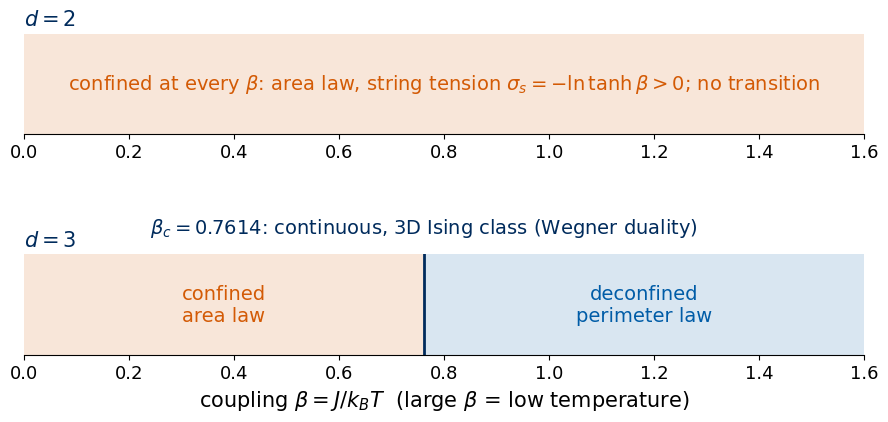

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_gauge_phase_diagram():
    beta_c = -0.5 * np.log(np.tanh(0.221654626))                   # Wegner duality with K_c of the 3D Ising model
    fig, (ax2, ax3) = plt.subplots(2, 1, figsize=(10, 4.4))
    fig.subplots_adjust(left=0.13, right=0.97, bottom=0.17, top=0.9, hspace=1.2)
    bmax = 1.6
    # 2D: confined at every finite beta, no transition
    ax2.axvspan(0, bmax, color=ORANGE, alpha=0.15, lw=0)
    ax2.text(bmax / 2, 0.5, r"confined at every $\beta$: area law, string tension $\sigma_s=-\ln\tanh\beta>0$; no transition",
             ha="center", va="center", fontsize=14, color=ORANGE)
    ax2.set_title("$d=2$", fontsize=15, color=NAVY, loc="left")
    # 3D: confined below beta_c, deconfined above
    ax3.axvspan(0, beta_c, color=ORANGE, alpha=0.15, lw=0); ax3.axvspan(beta_c, bmax, color=BLUE, alpha=0.15, lw=0)
    ax3.axvline(beta_c, color=NAVY, lw=2)
    ax3.text(beta_c / 2, 0.5, "confined\narea law", ha="center", va="center", fontsize=14, color=ORANGE)
    ax3.text((beta_c + bmax) / 2, 0.5, "deconfined\nperimeter law", ha="center", va="center", fontsize=14, color=BLUE)
    ax3.text(beta_c, 1.15, rf"$\beta_c={beta_c:.4f}$: continuous, 3D Ising class (Wegner duality)", ha="center", va="bottom",
             fontsize=14, color=NAVY, transform=ax3.get_xaxis_transform())
    ax3.set_title("$d=3$", fontsize=15, color=NAVY, loc="left")
    for ax in (ax2, ax3):
        ax.set_xlim(0, bmax); ax.set_yticks([]); ax.spines[["left", "top", "right"]].set_visible(False)
        ax.tick_params(labelsize=13)
    ax3.set_xlabel(r"coupling $\beta=J/k_BT$  (large $\beta$ = low temperature)", fontsize=15)
    return fig

with plt.rc_context({**SKETCH_STYLE, "figure.dpi": 100}):
    fig = sketch_gauge_phase_diagram()
plt.show()


<hr/>
## 6. Gauge redundancy

Elitzur's argument extends to any product of links. Let $S$ be a set of links and $\sigma_S=\prod_{l\in S}\sigma_l$. A gauge transformation at site $x$ multiplies $\sigma_S$ by $g(x)^{n_x(S)}$, where $n_x(S)$ is the
number of links of $S$ touching $x$. So $\sigma_S$ is gauge invariant only if every $n_x(S)$ is even, i.e. $S$ is a **closed** set of loops; otherwise the argument of Section 3.2 gives
$\langle\sigma_S\rangle=0$. This has two consequences for data analysis.

The first is that **every single link and every pair of links averages to zero**: $\langle\sigma_l\rangle=0$ and $\langle\sigma_l\sigma_{l'}\rangle=\delta_{ll'}$, because two distinct links never form a closed loop.
The covariance matrix of the raw links is the identity matrix **at every temperature**. Any method that uses only means and covariances of the raw variables (a linear classifier,
principal component analysis (PCA), a Gaussian model) sees the same featureless data at every $\beta$.

The second is that **the smallest non-trivial correlations involve four links around a plaquette**. A model on raw links has to discover four-point products, and a model that is not built to look at
neighbouring links together (a fully connected network has no notion of which links are neighbours) faces a search over a huge number of possible combinations.
A convolution with a small kernel sees one plaquette at a time, which is consistent with the CNN result of Carrasquilla and Melko.

Gauge-invariant features avoid the problem. Plaquettes $U_p$ (local, gauge invariant) and Wilson loops (non-local, gauge invariant) carry all the physical information, and feeding plaquettes instead of
links removes the redundancy by construction.

We check the first statement on the 3D data, comparing the covariance of raw links with the covariance of plaquettes, pooled over all couplings.

In [28]:
L = 8
links = ds3[L]["links"]                                            # (n_beta, n_samples, 3, L, L, L)
n_b, n_s = links.shape[:2]
X_links = links.reshape(n_b * n_s, -1).astype(np.float32)          # (n_beta * n_samples, 3 L^3)  raw features
X_plaq = np.asarray(jax.vmap(plaquettes)(jnp.asarray(links.reshape((-1, 3) + (L,) * 3), jnp.float32))).reshape(n_b * n_s, -1)
beta_of_row = np.repeat(BETAS_3D, n_s)
print("raw links:", X_links.shape, "  plaquettes:", X_plaq.shape, "  (rows = configurations, columns = features)")

X_noise = rng.choice(np.array([-1.0, 1.0], np.float32), size=X_links.shape)   # independent random +-1 entries, same shape
for name, X in (("raw links", X_links), ("plaquettes", X_plaq), ("pure noise", X_noise)):
    C = np.cov(X, rowvar=False)
    off = C - np.diag(np.diag(C))
    ev = np.linalg.eigvalsh(C)[::-1]
    print(f"{name:10s}: mean = {X.mean():+.4f}   diag(C) in [{np.diag(C).min():.3f}, {np.diag(C).max():.3f}]   max |off-diagonal| = {np.abs(off).max():.3f}"
          f"   top eigenvalues = {np.round(ev[:3], 2)}   median eigenvalue = {np.median(ev):.3f}")

# per coupling: link correlations of neighbouring links stay zero, plaquette mean carries beta
print("\n beta   <sigma_l>    <sigma_l sigma_l'> (two links of one plaquette)    <U_p>")
for bv in (0.4, 0.76, 1.1):
    i = int(np.argmin(np.abs(BETAS_3D - bv))); Ul = links[i].astype(np.float32)
    pair = (Ul[:, 0] * np.roll(Ul[:, 1], -1, axis=1)).mean()        # sigma_0(x) sigma_1(x + e_0): two sides of plaquette (x; 01)
    print(f" {BETAS_3D[i]:.2f}   {Ul.mean():+.4f}      {pair:+.4f}                                        {st3[L]['U'][i]:.4f}")

raw links: (29696, 1536)   plaquettes: (29696, 1536)   (rows = configurations, columns = features)


raw links : mean = +0.0000   diag(C) in [1.000, 1.000]   max |off-diagonal| = 0.032   top eigenvalues = [1.5 1.5 1.5]   median eigenvalue = 0.982


plaquettes: mean = +0.8193   diag(C) in [0.310, 0.345]   max |off-diagonal| = 0.082   top eigenvalues = [78.51  0.72  0.71]   median eigenvalue = 0.255


pure noise: mean = -0.0001   diag(C) in [1.000, 1.000]   max |off-diagonal| = 0.028   top eigenvalues = [1.5  1.5  1.49]   median eigenvalue = 0.983

 beta   <sigma_l>    <sigma_l sigma_l'> (two links of one plaquette)    <U_p>
 0.40   +0.0005      +0.0005                                        0.3948
 0.76   +0.0021      +0.0001                                        0.9523
 1.10   +0.0019      -0.0000                                        0.9986


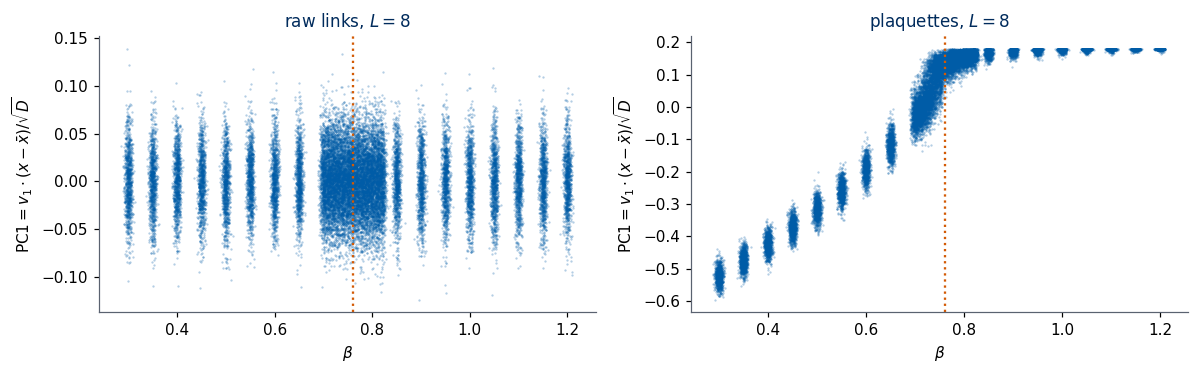

In [29]:
# projection on the leading principal component of the pooled data, against beta
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, (name, X) in zip(ax, (("raw links", X_links), ("plaquettes", X_plaq))):
    Xc = X - X.mean(0)
    v1 = np.linalg.eigh(np.cov(X, rowvar=False))[1][:, -1]           # leading eigenvector of the covariance
    pc1 = Xc @ v1 / np.sqrt(X.shape[1])
    a.plot(beta_of_row + rng.normal(0, 0.004, beta_of_row.size), pc1, ".", ms=1, alpha=0.3, color=UJBlue)
    a.axvline(BETA_C, color=DSOrange, ls=":", lw=1.5)
    a.set_xlabel(r"$\beta$"); a.set_ylabel(r"$\mathrm{PC1}=v_1\cdot(x-\bar x)/\sqrt{D}$"); a.set_title(f"{name}, $L={L}$")
plt.tight_layout(); plt.show()

The covariance of the raw links is the identity matrix up to sampling noise. Its diagonal, its largest off-diagonal entry ($0.032$) and its eigenvalue range coincide with those of a
matrix of independent random $\pm1$ entries of the same shape ($0.028$ for the largest off-diagonal entry); the spread of the eigenvalues around $1$ is a finite-sample effect of estimating a $D\times D$ covariance,
with $D=3L^3$ features, from a finite number of rows. There is no linear structure, and the first principal component is a random direction that does not depend on $\beta$. For plaquettes one eigenvalue ($78.5$) stands out,
its eigenvector is close to the uniform vector, and the projection on it is the plaquette average, which tracks $\beta$ and changes fastest around $\beta_c$.

This is the starting point of the anomaly-detection study later in Lecture 5, which uses the data sets saved here and compares representations (raw links, plaquettes, Wilson loops)
by whether an unsupervised model detects that something changes at $\beta_c$.

<hr/>
## 7. Summary

The table collects the main statements of the notebook and the sections in which each is derived and checked.

| statement | where it is derived and checked |
|---|---|
| spins on links, $U_p$ = product of 4 links, $H=-J\sum_pU_p$, $\beta=J/k_BT$ | Section 2 |
| heat-bath Monte Carlo, checkerboard per direction, `lax.scan` + `vmap` | Section 2.1; checked against exact $4\times4$ results (4.3) and $2\times2\times2$ enumeration |
| gauge symmetry $\sigma_\mu(x)\to g(x)\sigma_\mu(x)g(x+\hat e_\mu)$; $2^{N-1}$ transformations, $2^{dN-N+1}$ orbits | Section 3 (SymPy, $3\times3$ enumeration) |
| Elitzur: $\langle\sigma_l\rangle=0$; link "order" decays with an $L$-independent time, Ising magnetisation does not | Section 3.2 |
| 2D: $Z=2^N[(2\cosh\beta)^N+(2\sinh\beta)^N]$; $\langle U_p\rangle=\tanh\beta$, $c=\beta^2/\cosh^2\beta$, no transition | Sections 4.1–4.3 (enumeration + SymPy + MC) |
| 2D Wilson loops: $W=(\tanh\beta)^{A}$, area law, confinement at all $T$ | Section 4.4 |
| ground states: $4$ topological sectors in 2D, $2^d$ in $d$ dimensions; mixed at $T>0$ in 2D | Section 4.5 |
| 3D: cube constraint, flux loops; Wegner duality $\tanh K=e^{-2\beta}$; $\beta_c=-\frac12\ln\tanh K_c^I$ | Sections 5.1–5.2 |
| duality energy relation tested with independent Ising and gauge simulations | Section 5.3 |
| 3D MC: steep $\langle U_p\rangle$, sharp specific-heat peak, area law → perimeter law, Creutz ratio | Sections 5.4–5.5 |
| raw links: covariance = identity at all $\beta$; information sits in closed loops | Section 6 |

In [30]:
print(f"beta_c (3D Z2 gauge, from duality) = {BETA_C:.6f};   K_c (3D Ising) = {KC_I}")
for L in st3:
    print(f"L = {L:2d}: <U_p> at the coupling closest to beta_c ({BETAS_3D[np.argmin(np.abs(BETAS_3D - BETA_C))]:.2f}) = "
          f"{st3[L]['U'][np.argmin(np.abs(BETAS_3D - BETA_C))]:.4f}")
for f in sorted(os.listdir(DATA)):
    if f.startswith("z2gauge"):
        z = np.load(f"{DATA}/{f}")
        print(f"{f.removesuffix('.npz')}: links {z['links'].shape} {z['links'].dtype}, beta in [{z['beta'].min():.2f}, {z['beta'].max():.2f}] ({len(z['beta'])} values), "
              f"n_rep = {int(z['n_rep'])}, n_equil = {int(z['n_equil'])}, n_between = {int(z['n_between'])}")
print(f"total notebook running time: {(time.perf_counter() - T_NOTEBOOK) / 60:.1f} min")

beta_c (3D Z2 gauge, from duality) = 0.761413;   K_c (3D Ising) = 0.221654626
L =  6: <U_p> at the coupling closest to beta_c (0.76) = 0.9519
L =  8: <U_p> at the coupling closest to beta_c (0.76) = 0.9523
L = 10: <U_p> at the coupling closest to beta_c (0.76) = 0.9495
z2gauge_2d_L16: links (24, 512, 2, 16, 16) int8, beta in [0.10, 2.40] (24 values), n_rep = 16, n_equil = 500, n_between = 4


z2gauge_2d_L32: links (24, 512, 2, 32, 32) int8, beta in [0.10, 2.40] (24 values), n_rep = 16, n_equil = 500, n_between = 4


z2gauge_3d_L10: links (29, 1024, 3, 10, 10, 10) int8, beta in [0.30, 1.20] (29 values), n_rep = 16, n_equil = 600, n_between = 4


z2gauge_3d_L6: links (29, 1024, 3, 6, 6, 6) int8, beta in [0.30, 1.20] (29 values), n_rep = 16, n_equil = 600, n_between = 4


z2gauge_3d_L8: links (29, 1024, 3, 8, 8, 8) int8, beta in [0.30, 1.20] (29 values), n_rep = 16, n_equil = 600, n_between = 4
total notebook running time: 7.2 min


<hr/>
## Exercises

### Exercise 1 — Open strings
Take the product of links along an **open** straight path of length $n$ (a "string"), $S_n(x)=\prod_{k=0}^{n-1}\sigma_0(x+k\hat e_0)$. Show that it is not gauge invariant
and that $\langle S_n\rangle=0$, then check it on the 2D data at large $\beta$. Compare with the closed loop $W(1,n)$, which contains the same string as one of its sides.

#### Solution

In [31]:
# the gauge transformation at the starting site x flips only the first link of the string: S_n -> -S_n, hence <S_n> = 0
L = 32; i = int(np.argmin(np.abs(BETAS_2D - 2.0)))
Ul = jnp.asarray(ds2[L]["links"][i], jnp.float32)
for n in (1, 2, 3):
    Sn = float(jnp.mean(jax.vmap(lambda U: line_prod(U[0], 0, n))(Ul)))
    W1n = float(jnp.mean(jax.vmap(lambda U: wilson_loop(U, n, 1))(Ul)))
    print(f"beta = {BETAS_2D[i]}: open string of length {n}: <S_n> = {Sn:+.4f};   closed loop W({n},1) = {W1n:.4f}  (tanh^{n} = {np.tanh(BETAS_2D[i])**n:.4f})")

beta = 2.0: open string of length 1: <S_n> = -0.0019;   closed loop W(1,1) = 0.9640  (tanh^1 = 0.9640)


beta = 2.0: open string of length 2: <S_n> = -0.0007;   closed loop W(2,1) = 0.9293  (tanh^2 = 0.9293)


beta = 2.0: open string of length 3: <S_n> = +0.0009;   closed loop W(3,1) = 0.8959  (tanh^3 = 0.8959)


In $S_n$ the starting site $x$ and the end site $x+n\hat e_0$ each touch one link of the path, the inner sites two. A gauge transformation with $g=-1$ only at $x$
multiplies $S_n$ by $-1$ and leaves the weight unchanged, so $\langle S_n\rangle=-\langle S_n\rangle=0$. Closing the path into a loop makes every site touch an even number of
its links, and the average becomes $(\tanh\beta)^{\rm area}$.

### Exercise 2 — Partition function of a strip
Using the maximal-tree argument, predict $Z$ for an **open** lattice of $2\times3$ plaquettes and verify it with `plaquette_sum_histogram` and SymPy.

#### Solution

In [32]:
# open lattice of Lx x Ly plaquettes: (Lx+1)(Ly+1) sites, Lx(Ly+1) + (Lx+1)Ly links;  Z = 2^(sites-1) (2 cosh beta)^(Lx Ly)
Lx, Ly = 2, 3
h = {(x, y): k for k, (x, y) in enumerate((x, y) for x in range(Lx) for y in range(Ly + 1))}
v = {(x, y): len(h) + k for k, (x, y) in enumerate((x, y) for x in range(Lx + 1) for y in range(Ly))}
masks = [(1 << h[(x, y)]) | (1 << v[(x + 1, y)]) | (1 << h[(x, y + 1)]) | (1 << v[(x, y)]) for x in range(Lx) for y in range(Ly)]
n_l, n_sites = len(h) + len(v), (Lx + 1) * (Ly + 1)
print(f"links = {n_l}, sites = {n_sites}, free links after tree gauge = {n_l - (n_sites - 1)} = plaquettes = {Lx * Ly}")
Z_enum = Z_from_hist(plaquette_sum_histogram(n_l, masks))
Z_pred = 2**(n_sites - 1) * (2 * sp.cosh(b))**(Lx * Ly)
print("Z_enum - 2^(sites-1) (2 cosh beta)^(plaquettes) =", sp.simplify((Z_enum - Z_pred).rewrite(sp.exp)))

links = 17, sites = 12, free links after tree gauge = 6 = plaquettes = 6
Z_enum - 2^(sites-1) (2 cosh beta)^(plaquettes) = 0


### Exercise 3 — Duality map and the 3D phases
(a) Tabulate the dual Ising coupling $K(\beta)=\operatorname{artanh}e^{-2\beta}$ for the 3D couplings of the data set and mark which side of $K_c^I$ each one lies on.
(b) Verify numerically that $\tanh\beta=e^{-2K}$ holds for the same pairs (the map is symmetric).

#### Solution

In [33]:
for bv in (0.3, 0.6, 0.7, BETA_C, 0.8, 0.9, 1.2):
    Kv = np.arctanh(np.exp(-2 * bv))
    side = "ordered Ising  <-> confined gauge" if Kv > KC_I + 1e-12 else ("critical" if abs(Kv - KC_I) < 1e-9 else "disordered Ising <-> deconfined gauge")
    print(f"beta = {bv:.6f}:  K = {Kv:.6f}   ({side});   tanh(beta) - exp(-2K) = {np.tanh(bv) - np.exp(-2 * Kv):+.1e}")

beta = 0.300000:  K = 0.616679   (ordered Ising  <-> confined gauge);   tanh(beta) - exp(-2K) = -5.6e-17
beta = 0.600000:  K = 0.310832   (ordered Ising  <-> confined gauge);   tanh(beta) - exp(-2K) = -1.1e-16
beta = 0.700000:  K = 0.251786   (ordered Ising  <-> confined gauge);   tanh(beta) - exp(-2K) = -1.1e-16
beta = 0.761413:  K = 0.221655   (critical);   tanh(beta) - exp(-2K) = +0.0e+00
beta = 0.800000:  K = 0.204709   (disordered Ising <-> deconfined gauge);   tanh(beta) - exp(-2K) = +0.0e+00
beta = 0.900000:  K = 0.166830   (disordered Ising <-> deconfined gauge);   tanh(beta) - exp(-2K) = +0.0e+00
beta = 1.200000:  K = 0.090968   (disordered Ising <-> deconfined gauge);   tanh(beta) - exp(-2K) = +0.0e+00


### Exercise 4 — Strong-coupling expansion in 3D
For small $\beta$ write $e^{\beta U_p}=\cosh\beta\,(1+tU_p)$, $t=\tanh\beta$, for every plaquette and expand the product. Summing over links, only sets of plaquettes in which every link
appears an even number of times survive: **closed surfaces**. In 2D on the infinite lattice there are none, which gives $\langle U_p\rangle=t$ exactly. In 3D the smallest closed surface is the
boundary of a cube (6 plaquettes, $N$ of them). Show that
$$
\langle U_p\rangle = t + 2t^5 + O(t^7)
$$
and compare with the Monte Carlo data at small $\beta$.

#### Solution

In [34]:
# Z = (cosh b)^(3N) 2^(3N) [1 + N t^6 + ...];  <U_p> = (1/3N) d ln Z / d b = t + (1/3N) (1 - t^2) d/dt ln(1 + N t^6) = t + 2 t^5 (1 - t^2) + ...
# ln Z per site to this order: 3 ln(2 cosh b) (3 plaquettes, 3 links per site) + tanh(b)^6 (one cube per site)
lnZ_site = 3 * sp.log(2 * sp.cosh(b)) + sp.tanh(b)**6
U_sc = sp.simplify(sp.diff(lnZ_site, b) / 3)                      # <U_p> = (1/3) d(ln Z / N)/d beta
U_sc_t = sp.simplify(U_sc.subs(b, sp.atanh(t)))
print("<U_p> =", U_sc_t, "=", sp.expand(U_sc_t), "  -> series:", sp.series(U_sc_t, t, 0, 7))
L = 10
for bv in (0.30, 0.35, 0.40, 0.45, 0.50):
    i = int(np.argmin(np.abs(BETAS_3D - bv))); tv = np.tanh(BETAS_3D[i])
    print(f"beta = {BETAS_3D[i]:.2f}:  MC {st3[L]['U'][i]:.5f} +- {st3[L]['dU'][i]:.5f}   t = {tv:.5f}   t + 2t^5 = {tv + 2 * tv**5:.5f}")

<U_p> = -2*t**7 + 2*t**5 + t = -2*t**7 + 2*t**5 + t   -> series: t + 2*t**5 + O(t**7)
beta = 0.30:  MC 0.29470 +- 0.00066   t = 0.29131   t + 2t^5 = 0.29551
beta = 0.35:  MC 0.34399 +- 0.00062   t = 0.33638   t + 2t^5 = 0.34499
beta = 0.40:  MC 0.39474 +- 0.00046   t = 0.37995   t + 2t^5 = 0.39579
beta = 0.45:  MC 0.44650 +- 0.00051   t = 0.42190   t + 2t^5 = 0.44863
beta = 0.50:  MC 0.50192 +- 0.00063   t = 0.46212   t + 2t^5 = 0.50427


Expanding the product gives $Z=(\cosh\beta)^{3N}2^{3N}\sum_{\text{closed surfaces}}t^{|S|}=(\cosh\beta)^{3N}2^{3N}(1+Nt^6+\dots)$, with $3N$ links giving the factor $2^{3N}$.
Then $\langle U_p\rangle=\frac1{3N}\frac{\partial\ln Z}{\partial\beta}=t+\frac{1-t^2}{3N}\frac{6Nt^5}{1+Nt^6}+\dots=t+2t^5+O(t^7)$ (the $N^2$ terms of pairs of cubes cancel in $\ln Z$,
as in Lab 012, Section 4). At $\beta\le0.4$ the Monte Carlo data follow $t+2t^5$ better than $t$ alone; the deviation grows as $\beta$ approaches the transition, where the expansion fails.

### Exercise 5 (open) — Wilson loops in the dual Ising model
The duality maps the Wilson loop $W(C)$ of the gauge theory to an Ising quantity: the ratio $Z_I^{(C)}/Z_I$, where $Z_I^{(C)}$ is the Ising partition function with the couplings
of all bonds piercing a surface bounded by $C$ reversed in sign (a frustrated "seam"). Argue why the area law of the gauge theory corresponds to the ordered Ising phase (the seam costs
an energy proportional to its area) and the perimeter law to the disordered phase.

<hr/>
## References

**Original papers**
* F. J. Wegner, *Duality in generalized Ising models and phase transitions without local order parameters*, J. Math. Phys. **12**, 2259 (1971), [doi:10.1063/1.1665530](https://doi.org/10.1063/1.1665530).
* K. G. Wilson, *Confinement of quarks*, Phys. Rev. D **10**, 2445 (1974), [doi:10.1103/PhysRevD.10.2445](https://doi.org/10.1103/PhysRevD.10.2445).
* R. Balian, J. M. Drouffe, C. Itzykson, *Gauge fields on a lattice. II. Gauge-invariant Ising model*, Phys. Rev. D **11**, 2098 (1975), [doi:10.1103/PhysRevD.11.2098](https://doi.org/10.1103/PhysRevD.11.2098).
* S. Elitzur, *Impossibility of spontaneously breaking local symmetries*, Phys. Rev. D **12**, 3978 (1975), [doi:10.1103/PhysRevD.12.3978](https://doi.org/10.1103/PhysRevD.12.3978).
* M. Creutz, L. Jacobs, C. Rebbi, *Experiments with a gauge-invariant Ising system*, Phys. Rev. Lett. **42**, 1390 (1979), [doi:10.1103/PhysRevLett.42.1390](https://doi.org/10.1103/PhysRevLett.42.1390).
* M. Creutz, *Monte Carlo study of quantized SU(2) gauge theory*, Phys. Rev. D **21**, 2308 (1980), [doi:10.1103/PhysRevD.21.2308](https://doi.org/10.1103/PhysRevD.21.2308) (the Creutz ratio).
* A. Yu. Kitaev, *Fault-tolerant quantum computation by anyons*, Ann. Phys. **303**, 2 (2003), [doi:10.1016/S0003-4916(02)00018-0](https://doi.org/10.1016/S0003-4916(02)00018-0), [arXiv:quant-ph/9707021](https://arxiv.org/abs/quant-ph/9707021).
* A. M. Ferrenberg, J. Xu, D. P. Landau, *Pushing the limits of Monte Carlo simulations for the three-dimensional Ising model*, Phys. Rev. E **97**, 043301 (2018),
  [doi:10.1103/PhysRevE.97.043301](https://doi.org/10.1103/PhysRevE.97.043301), [arXiv:1806.03558](https://arxiv.org/abs/1806.03558).
* J. Carrasquilla, R. G. Melko, *Machine learning phases of matter*, Nature Physics **13**, 431 (2017), [doi:10.1038/nphys4035](https://doi.org/10.1038/nphys4035),
  [arXiv:1605.01735](https://arxiv.org/abs/1605.01735) (the Ising gauge theory results quoted in Section 1 are in the arXiv version, main text and Appendix C).

**Review and textbooks**
* J. B. Kogut, *An introduction to lattice gauge theory and spin systems*, Rev. Mod. Phys. **51**, 659 (1979), [doi:10.1103/RevModPhys.51.659](https://doi.org/10.1103/RevModPhys.51.659).
* I. Montvay, G. Münster, *Quantum Fields on a Lattice*, Cambridge University Press (1994), [doi:10.1017/CBO9780511470783](https://doi.org/10.1017/CBO9780511470783).
* H. J. Rothe, *Lattice Gauge Theories: An Introduction*, 4th edition, World Scientific Lecture Notes in Physics, [doi:10.1142/8229](https://doi.org/10.1142/8229).
* C. Gattringer, C. B. Lang, *Quantum Chromodynamics on the Lattice: An Introductory Presentation*, Lecture Notes in Physics, Springer (2010), [doi:10.1007/978-3-642-01850-3](https://doi.org/10.1007/978-3-642-01850-3).
* J. Smit, *Introduction to Quantum Fields on a Lattice*, Cambridge University Press (2023), [doi:10.1017/9781009402705](https://doi.org/10.1017/9781009402705).